# Load data and compute missing metrics & rolling means

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

COLUMNS_TO_READ = [
    'frame',
    'ACCELERATION#wcentroid (cm/s2)',
    "SPEED#wcentroid (cm/s)",
    'X (cm)',
    'Y (cm)',
    'time',
]

In [2]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [3]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(
                        DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv",
                        usecols=COLUMNS_TO_READ,
                    )
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)

## Excludes ph1 trial 1 green river data.
# These data come at non-standard timestamps and it messes up the aggregation plots.
# It's unclear whether these data are otherwise valid.
df = df[
    ~((df["pH"] == 1) &
    (df["River"] == "Green") &
    (df["Trial"] == 1))]

In [4]:
# Radius correction
PH_TO_X_Y_RADIUS = {
    #   x center, y center, radius
    1: (3840/2 + 75, 2160/2, 1284),
    2: (3840/2 + 144, 2160/2, 1184),
    3: (3840/2 + 30, 2160/2 + 20, 1284),
}

# We don't actually want to save these columns to the dataframe, they're unnecessarily big.
# But doing it like this is in theory faster.
df["center x"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][0], axis=1)
df["center y"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][1], axis=1)
df["radius length"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][2], axis=1)

df["radius"] = compute_radius(
    df["X (cm)"],
    df["Y (cm)"],
    df["center x"],
    df["center y"],
) / df["radius length"]

df["X"] = (df["X (cm)"] - df["center x"])/df["radius length"]
df["Y"] = (df["Y (cm)"] - df["center y"])/df["radius length"]

In [5]:
# Rescale kinematics by radius length
df["speed"] = df["SPEED#wcentroid (cm/s)"] / df["radius length"]
df["acceleration"] = df["ACCELERATION#wcentroid (cm/s2)"]

In [6]:
# Throws out data points with infinite x or y (missing locations)
df = df[~(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]

# Throws out anomolous points with radius > a cutoff.
df = df[df["radius"] <= 1.0]

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
# We need to round back to 2 decimal points to avoid floating-point errors that will mess up the later
# seaborn aggregations by time.
df["skin_extract_injection_time"] = np.round(df["time"] - df["skin_extract_injection_seconds"], decimals=2)
df["visual_disturbance_time"] = np.round(df["time"] - df["visual_disturbance_seconds"], decimals=2)


In [7]:
COLUMNS_TO_KEEP = [
    "River", "pH", "Trial", "Individual",
    "time",
    "radius",
    "acceleration", "speed",
    "skin_extract_injection_time",
    "visual_disturbance_time",
    "X",
    "Y",
]
df = df[COLUMNS_TO_KEEP]

In [8]:
# Adds rolling means.
NAMES = [
    ("radius", "radius"),
    ("speed", "speed"),
    ("acceleration", "acceleration"),
    # ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15]#, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

acceleration 15          

In [9]:
# Add neighbor distances at every second (not every frame).
data = []

# Adds mean neighbor distances.
for _name, group_df in df[df["time"] % 1.0 == 0].groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X", "Y"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        mean_neighbor_dist = np.mean(pdist(fish_positions))
    else:
        mean_neighbor_dist = np.nan
    data.append((river, pH, trial, time, mean_neighbor_dist))


# # Another merge/join to get the neighbor dists into the larger dataframe.
by_trial = pd.DataFrame(data, columns = ["River", "pH", "Trial", "time", "meanneighbordist"])
df = df.merge(by_trial, on=["River", "pH", "Trial", "time"], how="left")
del(by_trial) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.



In [10]:
data = []
# Adds min neighbor distances for each fish.
for _name, group_df in df[df["time"] % 1.0 == 0].groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X", "Y"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        square = squareform(pdist(fish_positions))
        for i in range(6):
            min_neighbor_dist = np.min(np.delete(square[i], i))
            data.append((river, pH, trial, i, time, min_neighbor_dist))
    # else:
    #     mean_neighbor_dist = np.nan
    # break


    # data.append((river, pH, trial, time, min_neighbor_dist))

by_indiv = pd.DataFrame(data, columns = ["River", "pH", "Trial", "Individual", "time", "minneighbordist"])
df = df.merge(by_indiv, on=["River", "pH", "Trial", "Individual", "time"], how="left")
del(by_indiv)

# Look for startles

In [11]:
# Add 99th percentile here.
QUANTILES = [0.5, 0.9, 0.99]
COLUMNS = ["speed", "speed15", "acceleration"]
COLUMN_NAMES = ["River", "pH", "Trial", "Individual"]
for column in COLUMNS:
    for quantile in QUANTILES:
        COLUMN_NAMES.append(column + str(quantile))

data = []

for _name, group_df in df.groupby(["River", "pH", "Trial", "Individual"]):
    river, pH, trial, individual = _name
    

    row = [river, pH, trial, individual]

    for column in COLUMNS:
        for quantile in QUANTILES:
            row.append(group_df[column].quantile(quantile))
            

    data.append(row)

by_fish = pd.DataFrame(data, columns = COLUMN_NAMES)

<Axes: xlabel='speed0.99', ylabel='Count'>

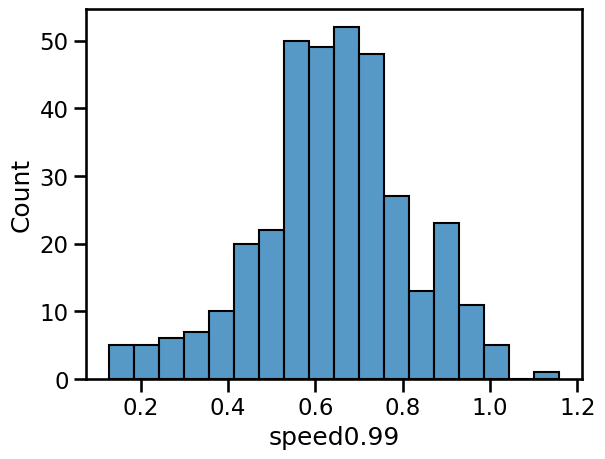

In [12]:
sns.histplot(data=by_fish, x="speed0.99")

<Axes: xlabel='speed150.99', ylabel='Count'>

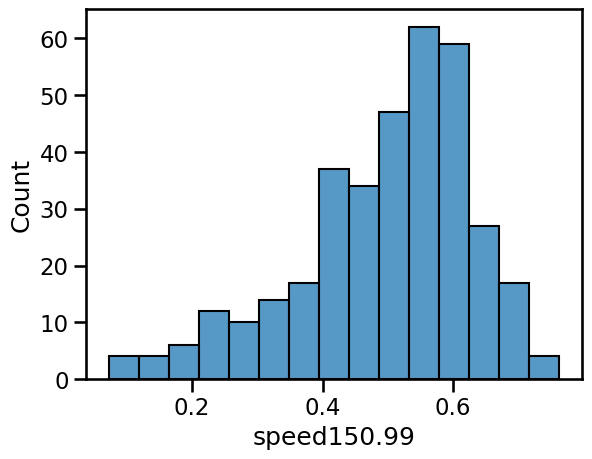

In [13]:
sns.histplot(data=by_fish, x="speed150.99")

In [14]:
df["speed15"].quantile([0.5, 0.90, 0.99])

0.50    0.060526
0.90    0.240088
0.99    0.567838
Name: speed15, dtype: float64

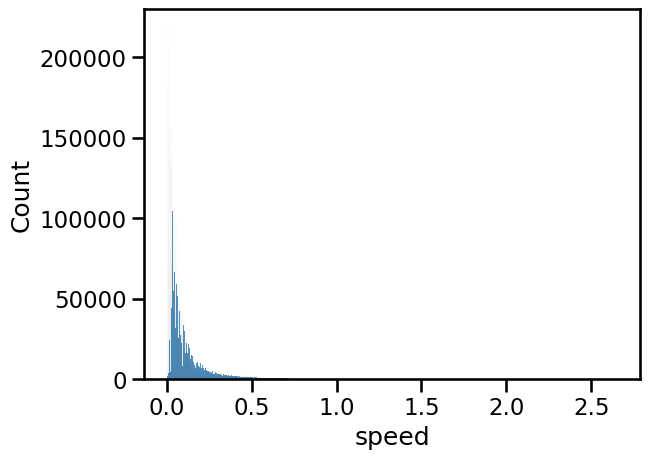

In [15]:
p = sns.histplot(df["speed"])
# p.set(xscale="log")

[None]

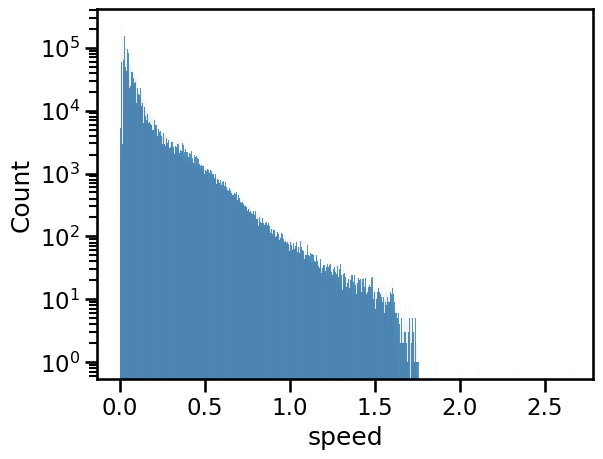

In [16]:
p = sns.histplot(df["speed"])
p.set(yscale="log")
# p.set(xscale="log")

In [17]:
# Looking for startle starts.

df["startle_raw"] = df["speed"] > 0.5
df["startle_smooth"] = df["speed15"] > 0.5
df["startle_raw_1"] = df["speed"] > 1.0
df["startle_smooth_1"] = df["speed15"] > 1.0

for (startle_var, start_var)  in [
    ("startle_raw", "startle_start_raw"),
    ("startle_smooth", "startle_start_smooth"),
    ("startle_raw_1", "startle_start_raw_1"),
    ("startle_smooth_1", "startle_start_smooth_1"),
    
]:
    
    COLUMN_NAMES = ["River", "pH", "Trial", "Individual", "time"]
    
    data = []
    
    for _name, group_df in df.groupby(["River", "pH", "Trial", "Individual"]):
        river, pH, trial, individual = _name
    
        print(f"\radding {startle_var} starts for {river} {pH} {trial} {individual}             ", end="")
    
        in_startle = False
        for _, r in group_df.iterrows():
            if not in_startle:
                if r[startle_var]:
                    in_startle = True
                    data.append([river, pH, trial, individual, r["time"]])
    
            else:
                if not r[startle_var]:
                    in_startle = False
    
    startle_starts = pd.DataFrame(data, columns = COLUMN_NAMES)
    
    startle_starts[start_var] = 1
    
    df = df.merge(startle_starts, on=["River", "pH", "Trial", "Individual", "time"], how="left")
    df[start_var] = df[start_var].fillna(0)

adding startle_smooth_1 starts for Skagit 3 10 5             

In [18]:
# Adds rolling means for startles.
NAMES = [
    ("startle_start_raw", "startle_start_raw"),
    ("startle_start_smooth", "startle_start_smooth"),
    ("startle_start_raw_1", "startle_start_raw_1"),
    ("startle_start_smooth_1", "startle_start_smooth_1"),
    # ("speed", "speed"),
    # ("acceleration", "acceleration"),
    # ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

startle_start_smooth_1 240          

# Sanity Check Plots

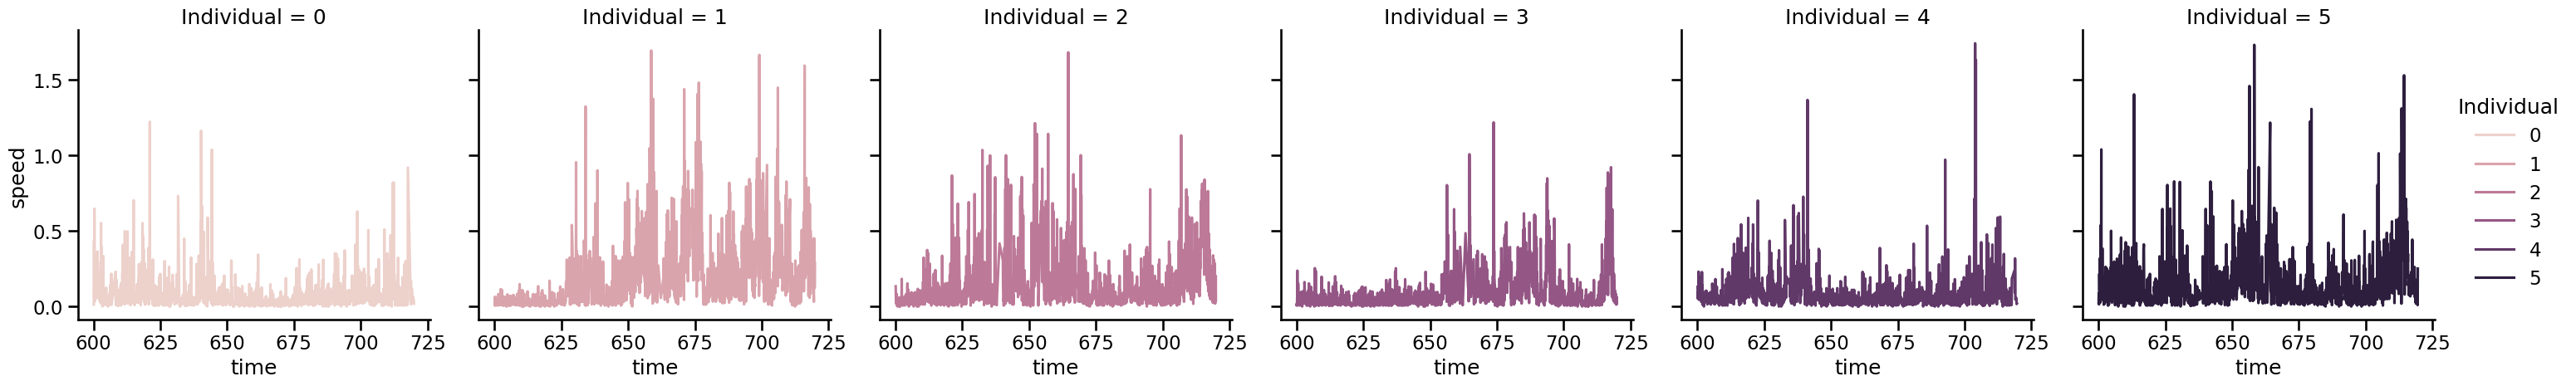

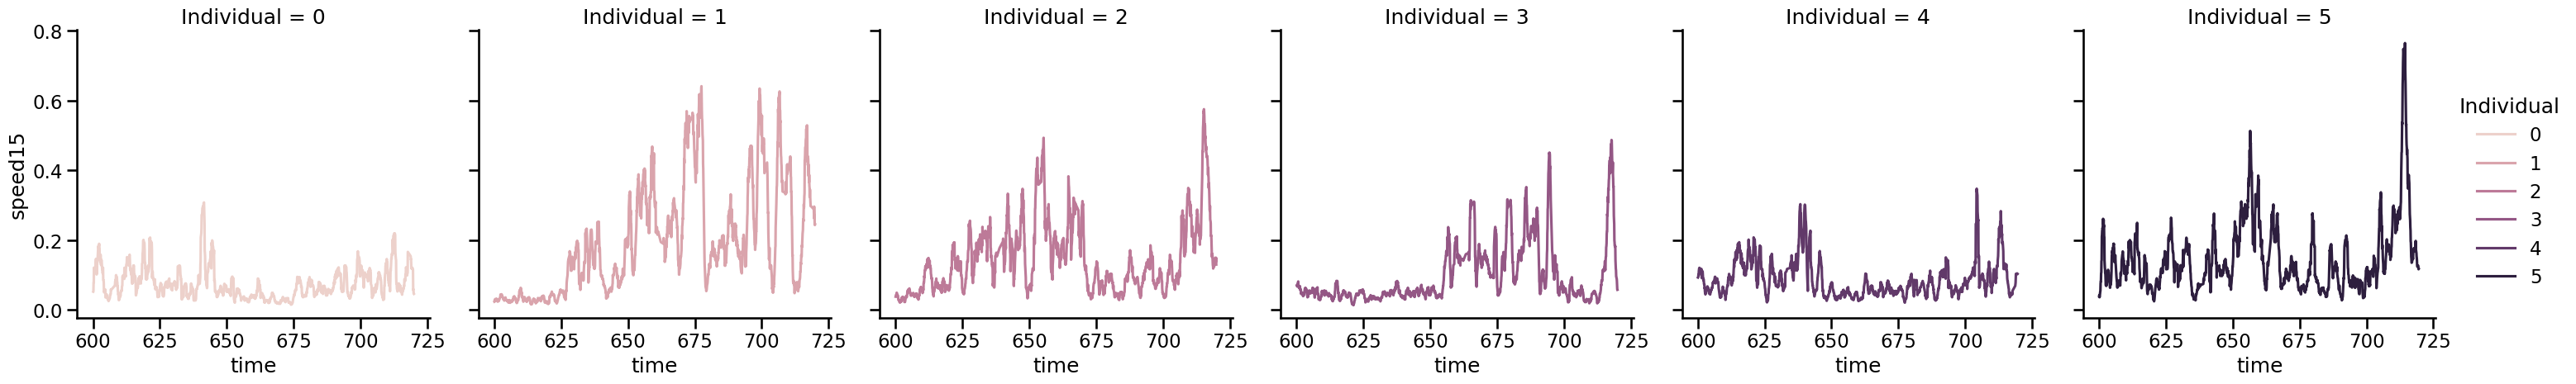

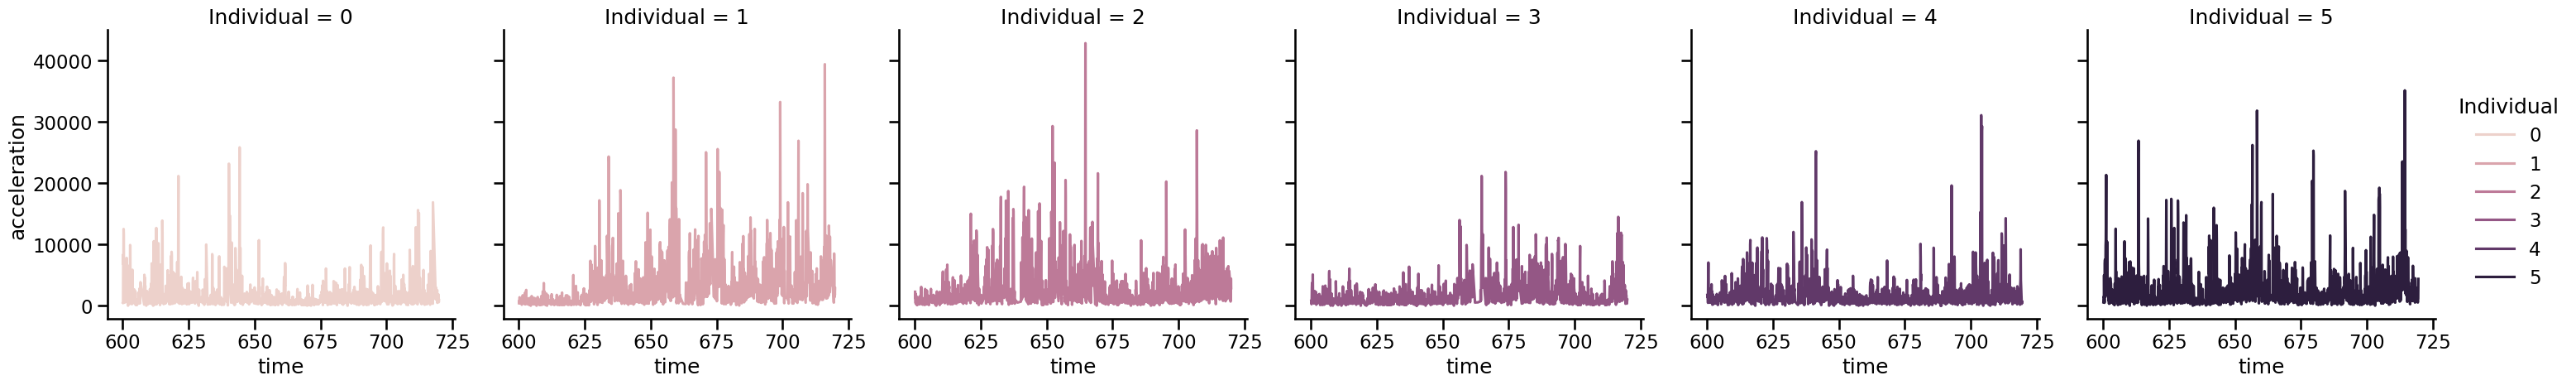

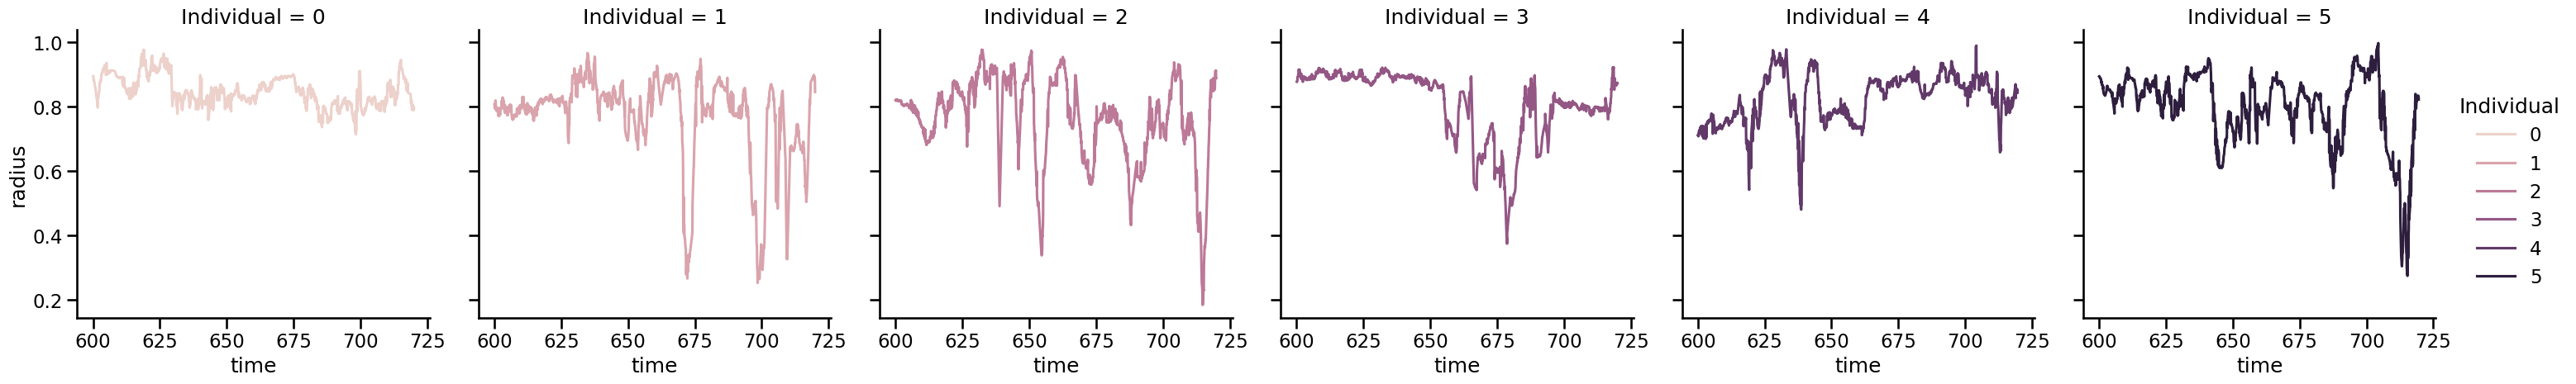

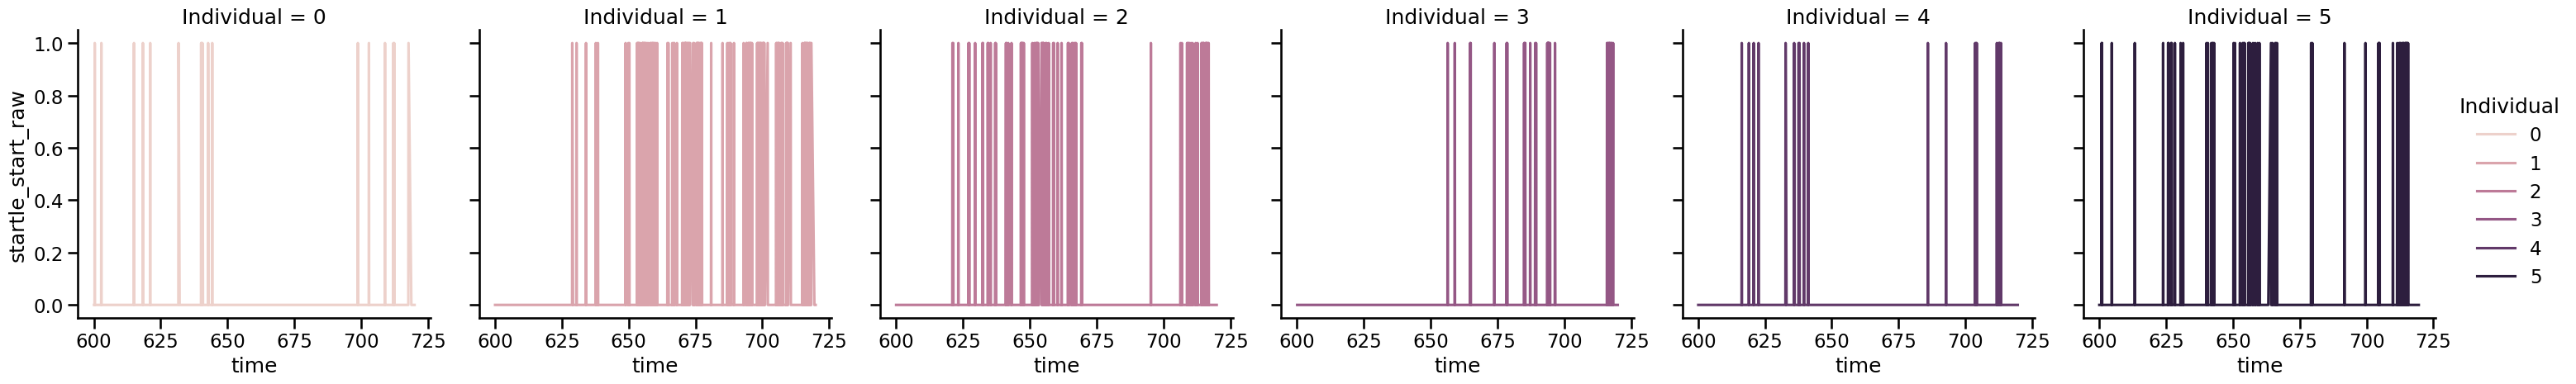

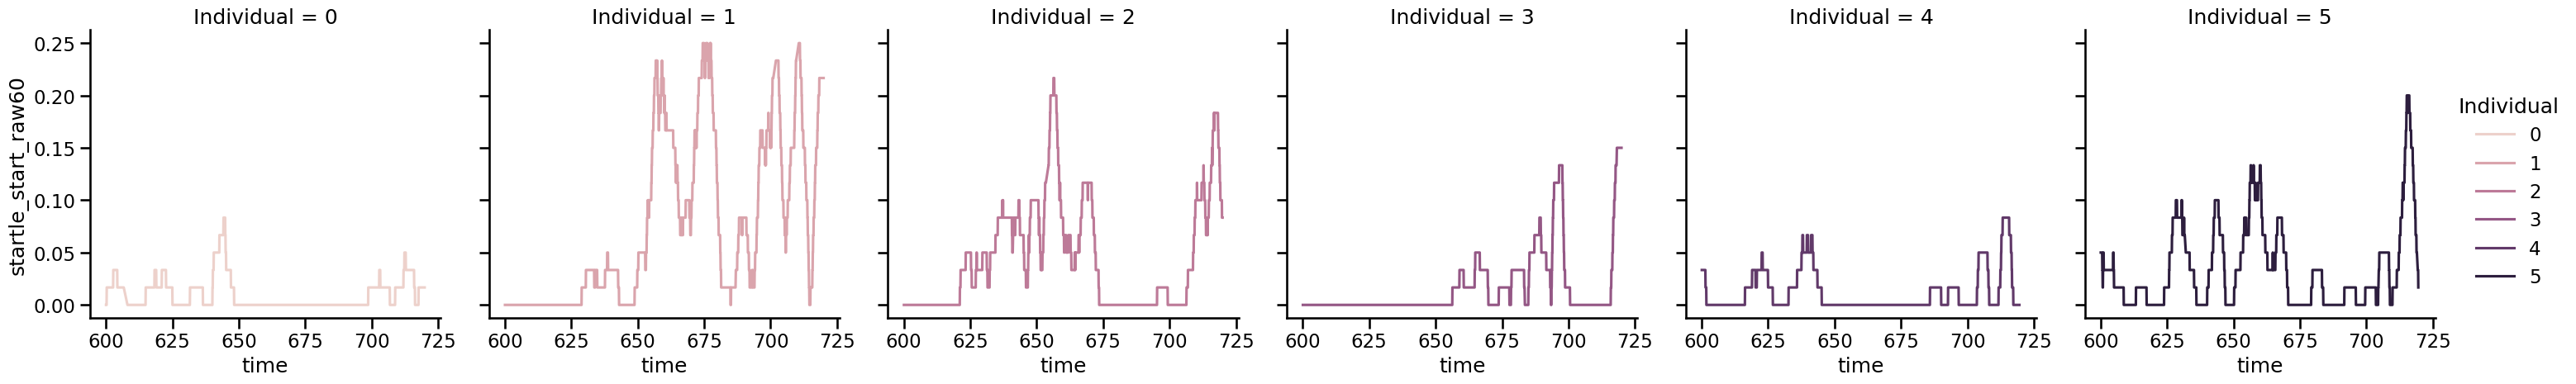

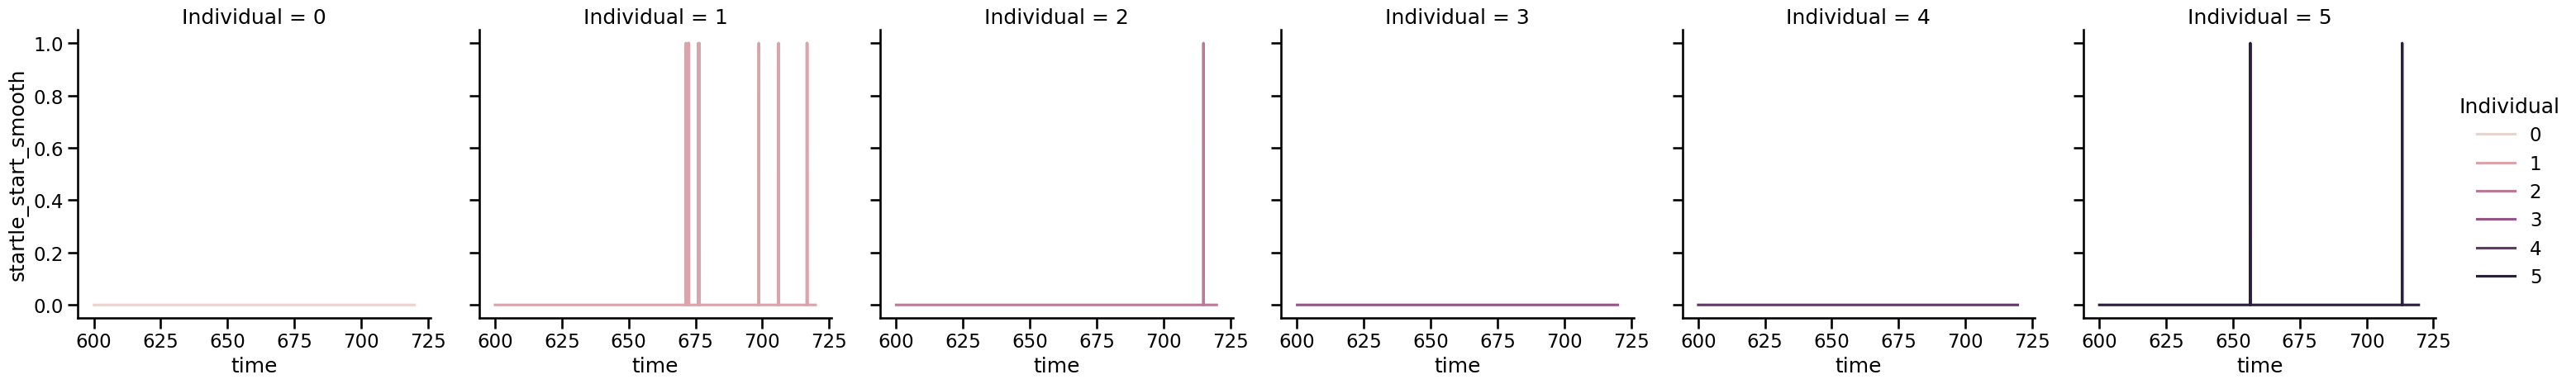

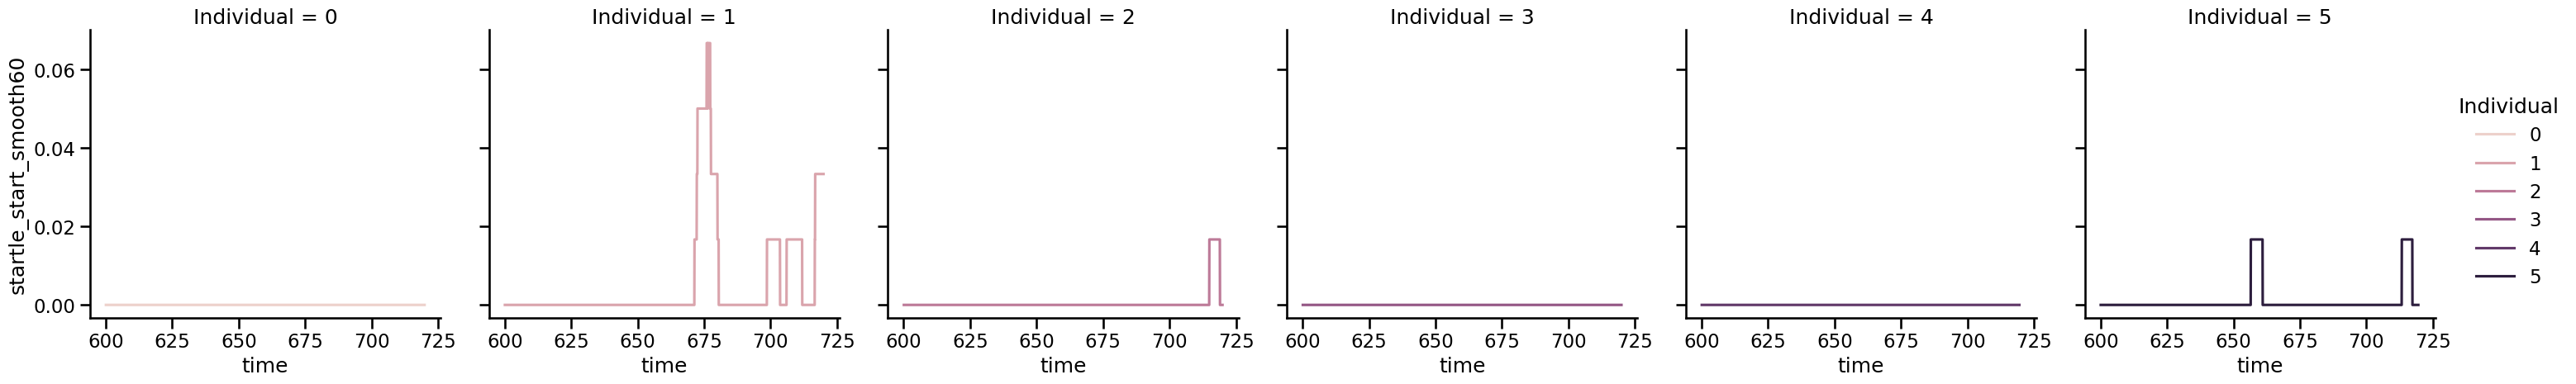

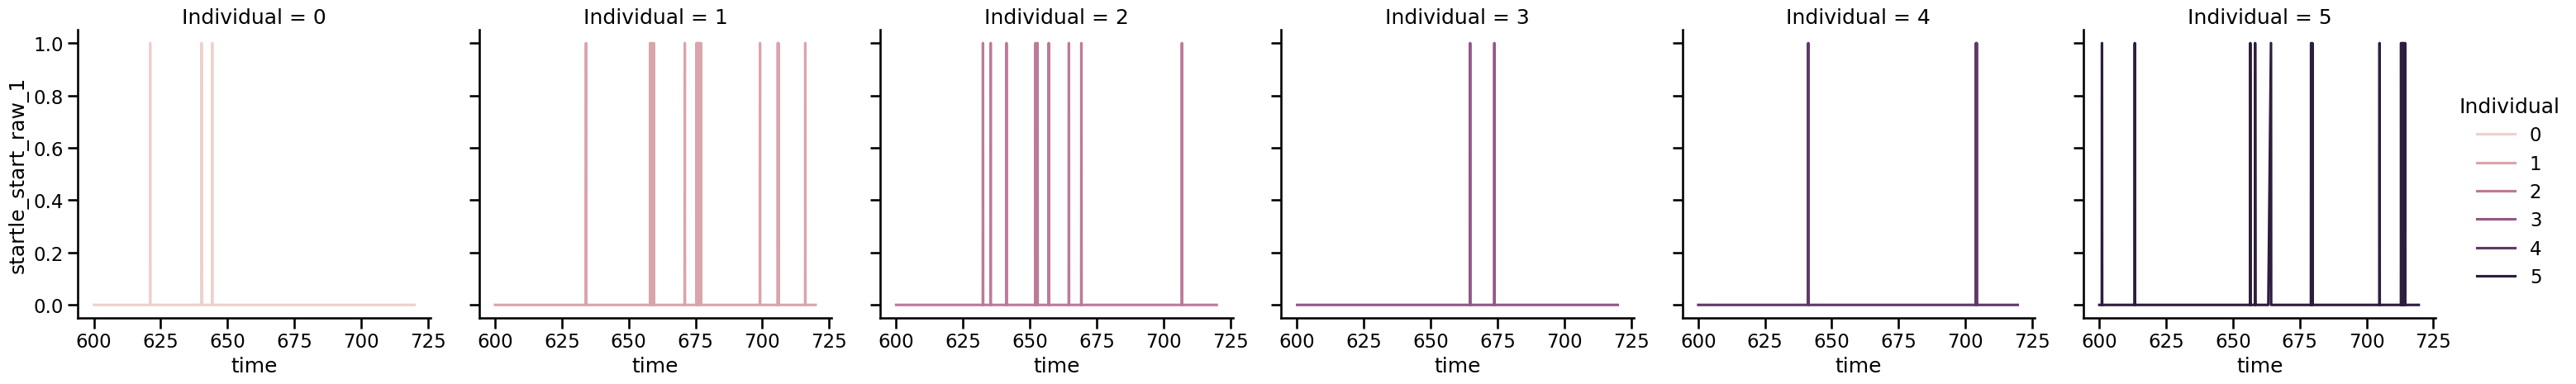

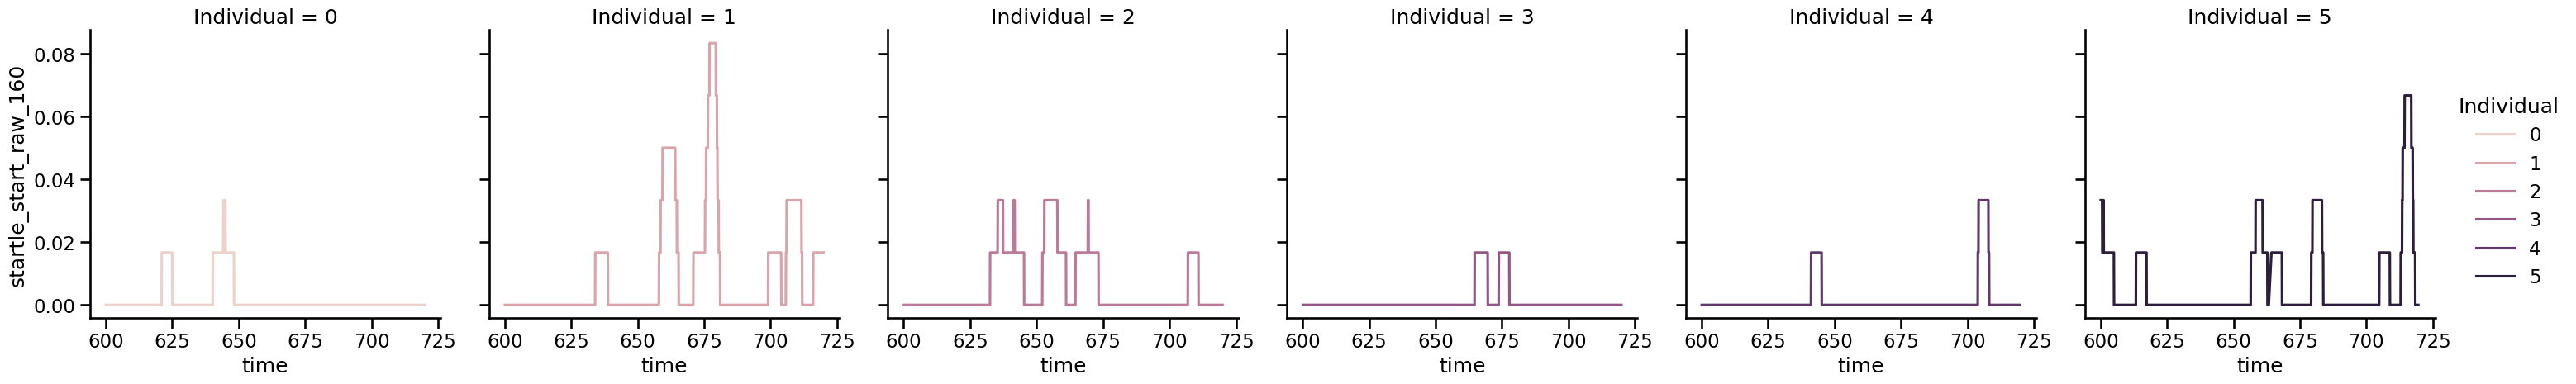

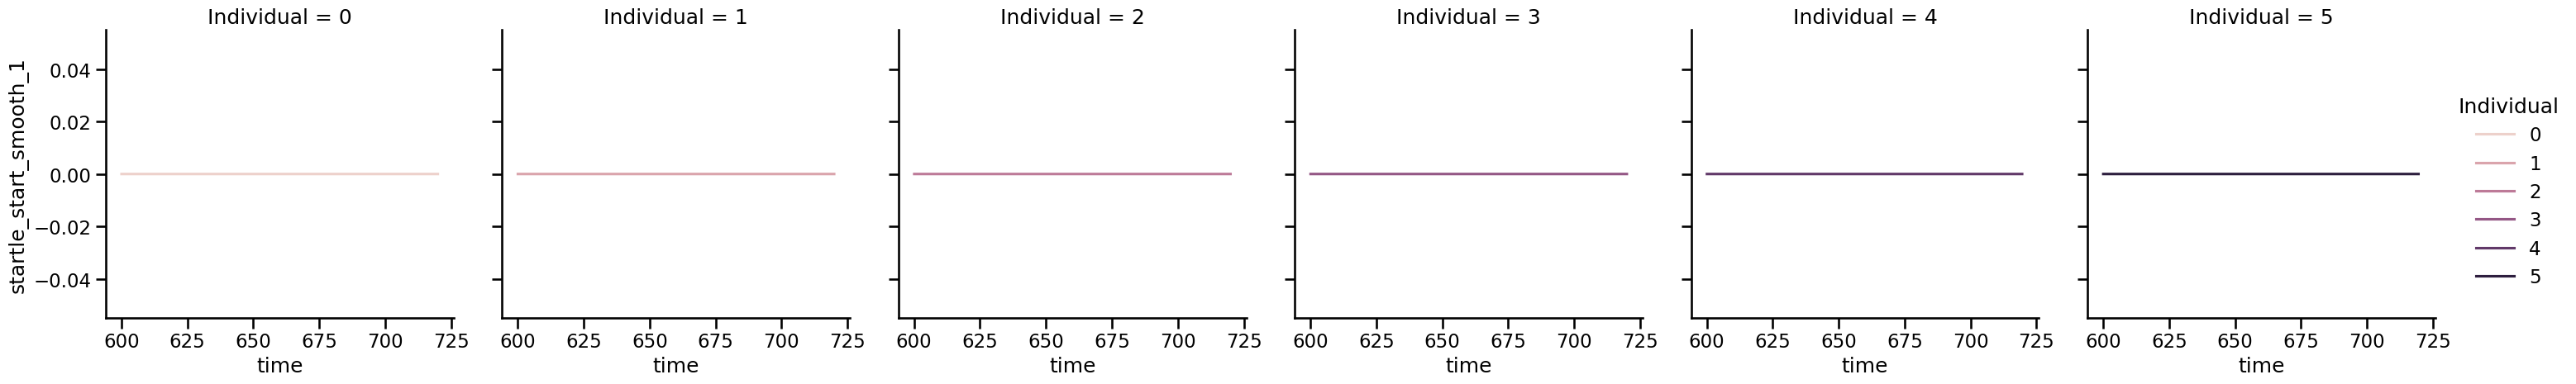

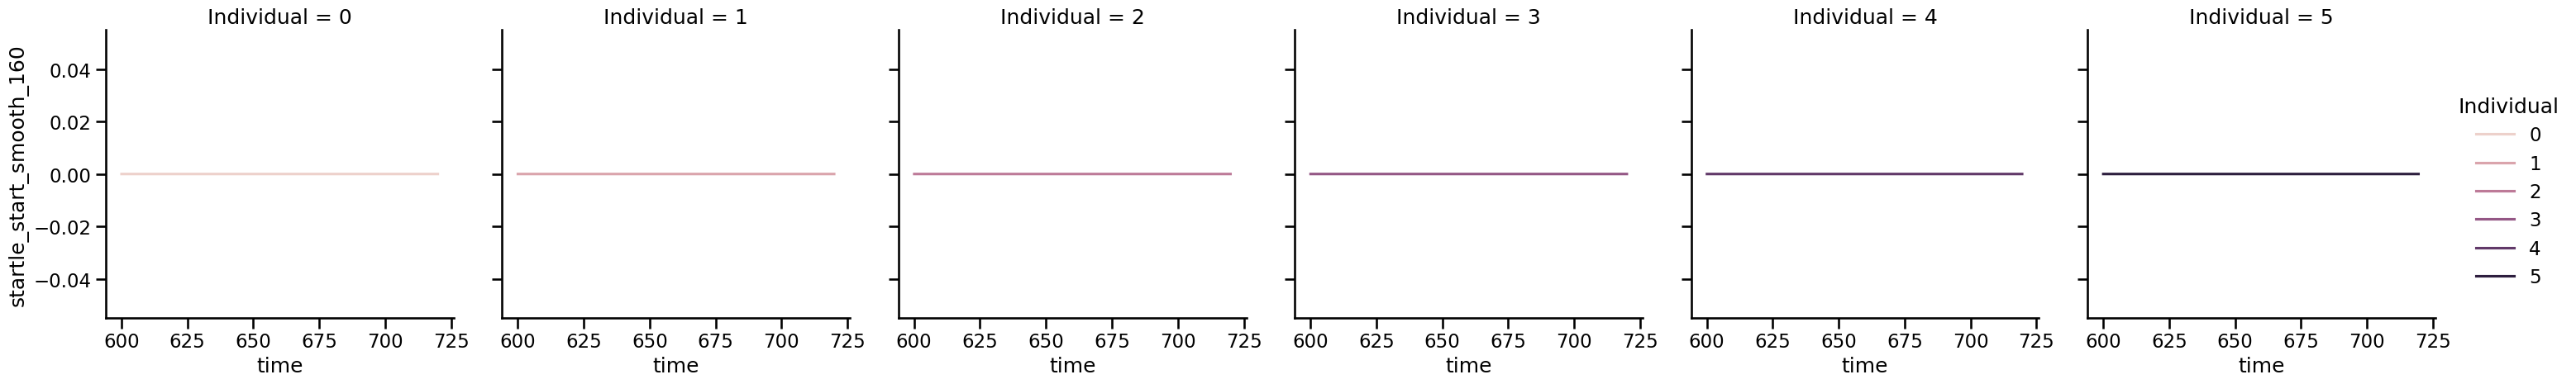

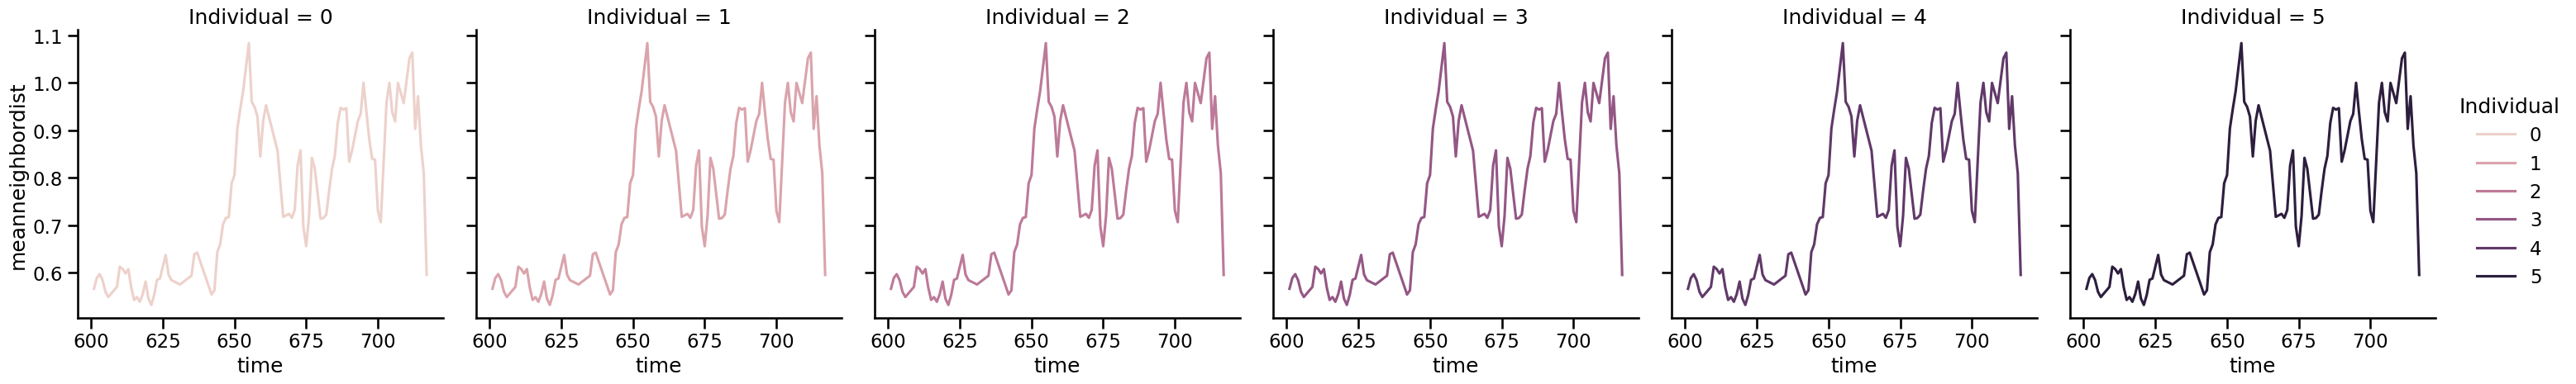

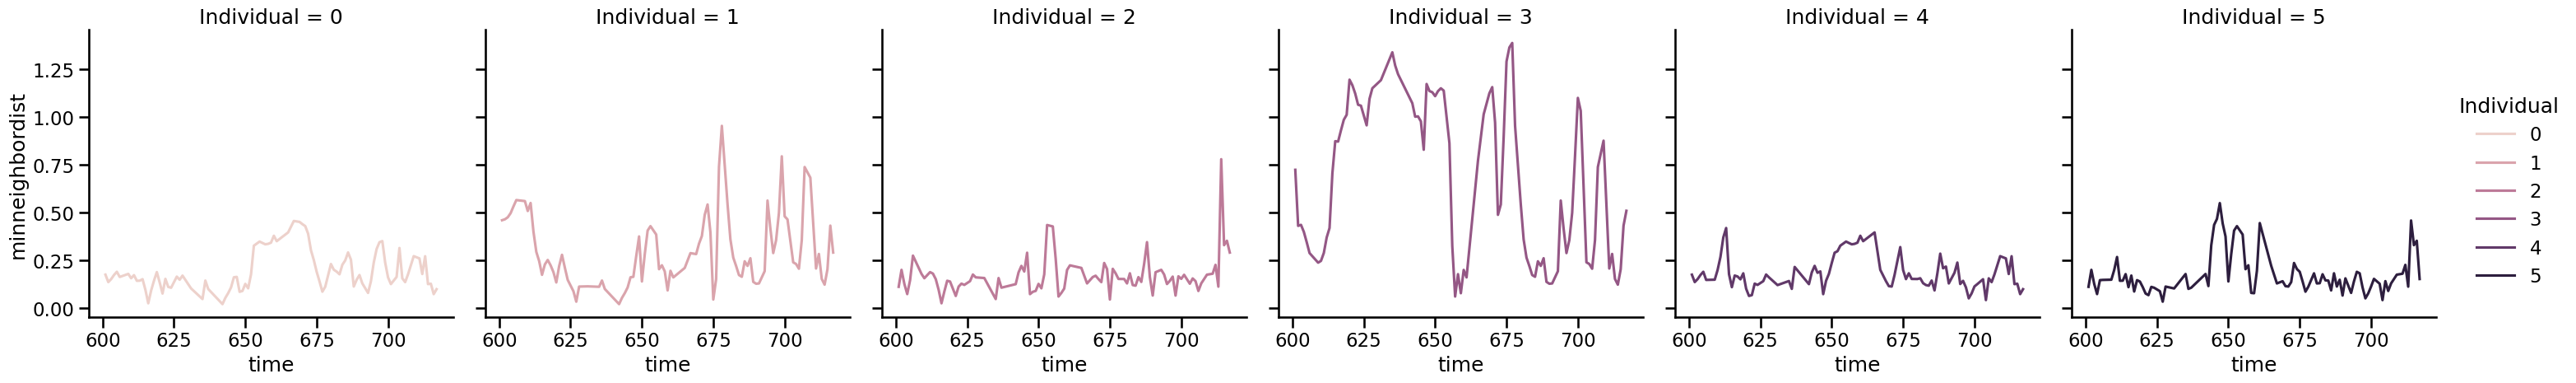

In [19]:
RIVER = "Skagit"
PH = 2
TRIAL = 6
VARIABLES = [
    # "X",
    # "Y",
    "speed",
    "speed15",
    "acceleration",
    # "acceleration0.99",
    "radius",
    "startle_start_raw",
    "startle_start_raw60",
    "startle_start_smooth",
    "startle_start_smooth60",
    "startle_start_raw_1",
    "startle_start_raw_160",
    "startle_start_smooth_1",
    "startle_start_smooth_160",
    "meanneighbordist",
    "minneighbordist",
]


one_video = df[
    (df["River"] == RIVER) &
    (df["pH"] == PH) &
    (df["Trial"] == TRIAL) &
    (df["time"] > 60 * 10) &
    (df["time"] < 60 * 12) &
    True
    ]

# sns.relplot(data=one_video, x="X", y="Y", hue="time", col="Individual")

for var in VARIABLES:
    p = sns.relplot(data=one_video, x="time", y=var, kind="line", hue="Individual", col="Individual", errorbar=None)

# Set up intervals & variables

In [20]:
VARIABLES = [
    "speed",
    "speed15",
    "acceleration",
    "acceleration15",
    "startle_start_raw",
    "startle_start_smooth",
    "startle_start_raw_1",
    "startle_start_smooth_1",
    "startle_start_smooth60",
    "startle_start_raw60",
    "startle_start_smooth_160",
    "startle_start_raw_160",
    "radius",
    "meanneighbordist",
    "minneighbordist",
]

# First 10 minutes
first_10 = df[
    (df["time"] > 60) &
    (df["time"] < 60 * 10)]

# 5 minutes before and after skin extract injection.
SKIN_EXTRACT_BEFORE = a, b = (-60 * 1, 0)
SKIN_EXTRACT_AFTER = c, d = (60 * 4, 60 * 5)
skin_extract_before = df[
    ((df["skin_extract_injection_time"] >= a) & (df["skin_extract_injection_time"] <= b))]
skin_extract_after = df[
     ((df["skin_extract_injection_time"] >= c) & (df["skin_extract_injection_time"] <= d))]

# visual disturbance.
VISUAL_DISTURBANCE_BEFORE = a, b = (-60, 0)
VISUAL_DISTURBANCE_AFTER_SHORT = c, d = (0, 2)
VISUAL_DISTURBANCE_AFTER_LONG = e, f = (2, 30)

visual_disturbance_before = df[
    (df["visual_disturbance_time"] >= a) & (df["visual_disturbance_time"] < b)]
visual_disturbance_after_short = df[
     ((df["visual_disturbance_time"] >= c) & (df["visual_disturbance_time"] < d))]
visual_disturbance_after_long = df[
     ((df["visual_disturbance_time"] >= e) & (df["visual_disturbance_time"] < f))]


# Qualitative Plots

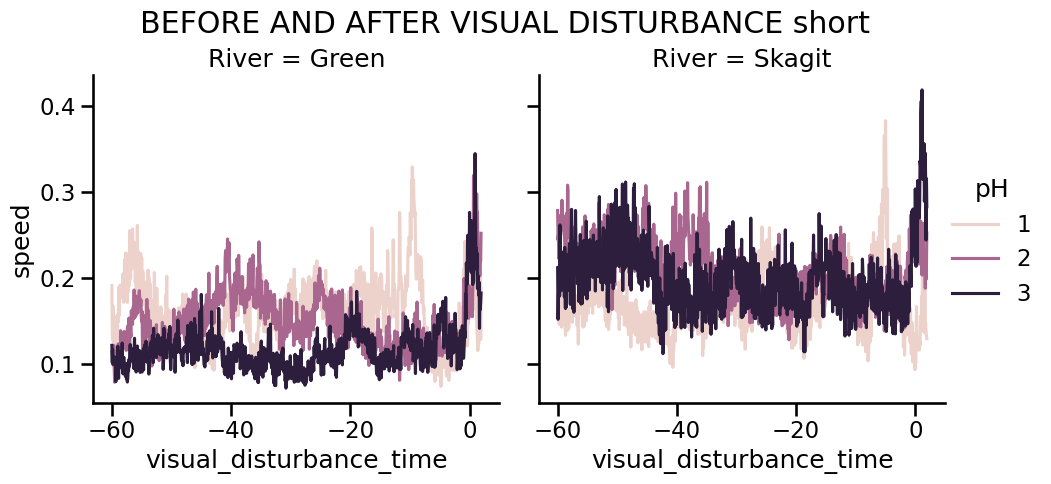

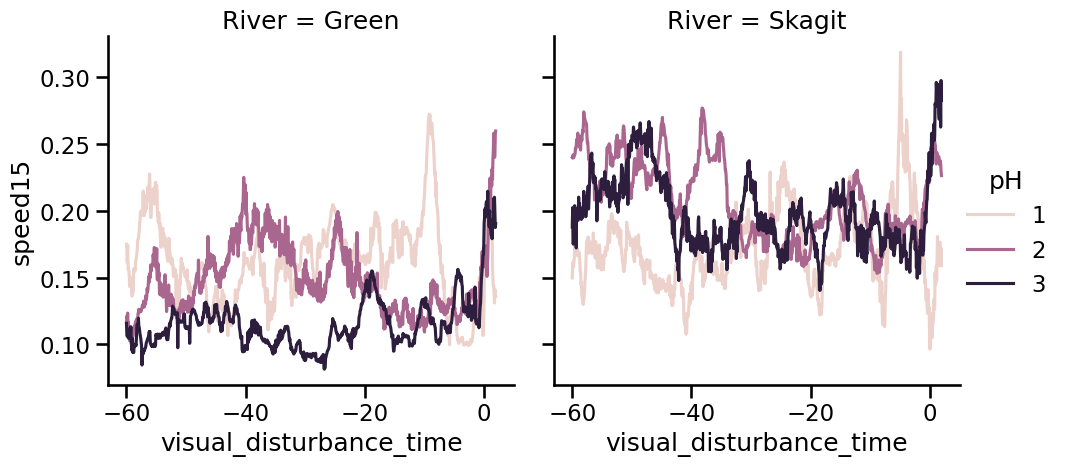

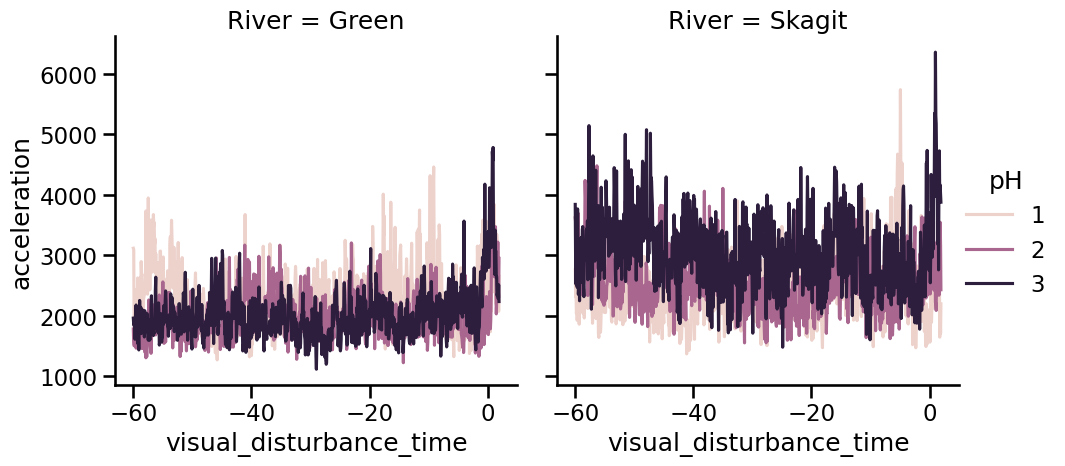

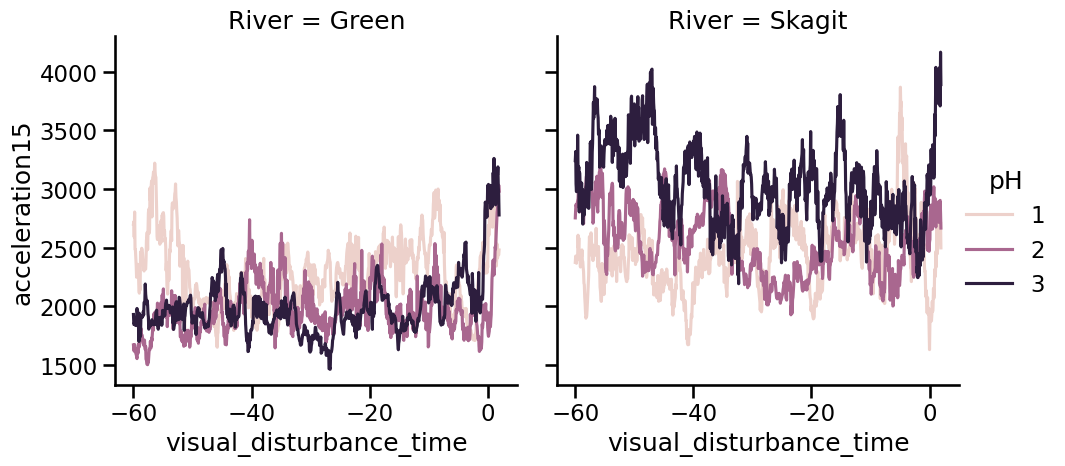

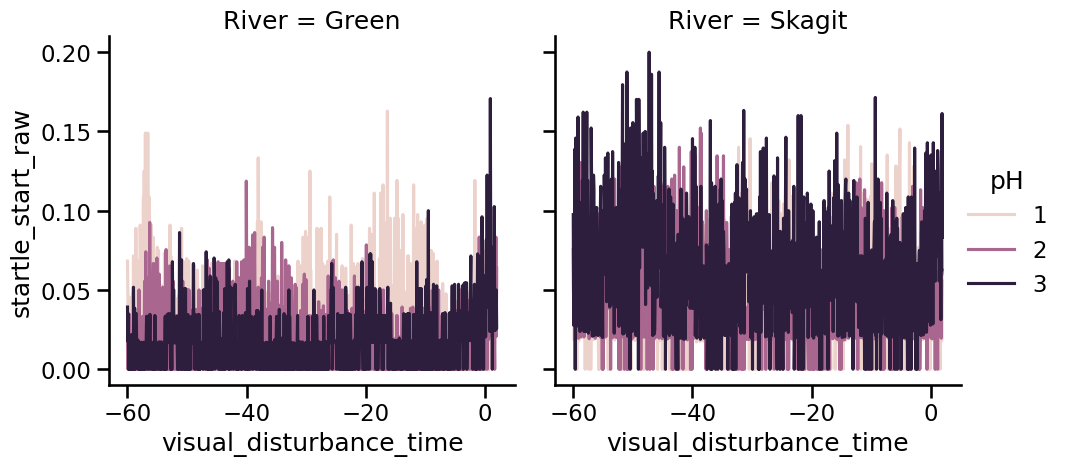

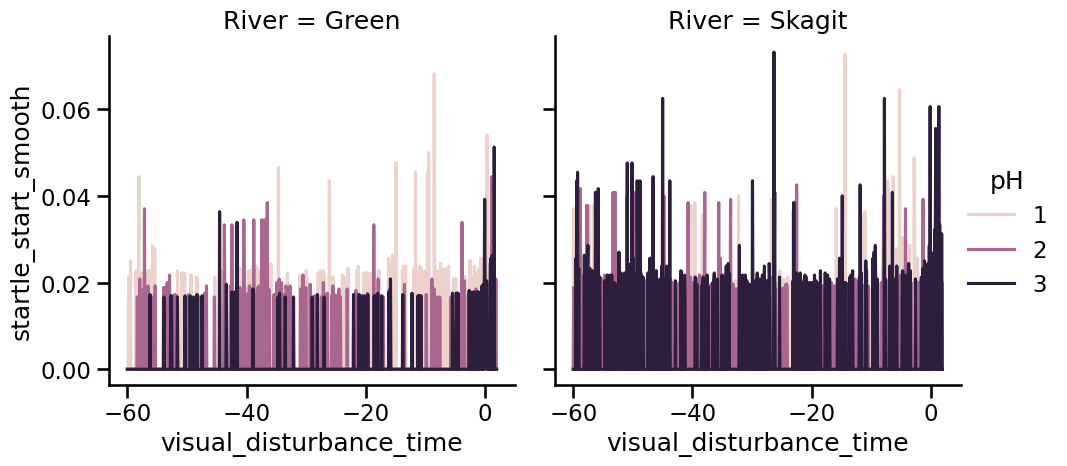

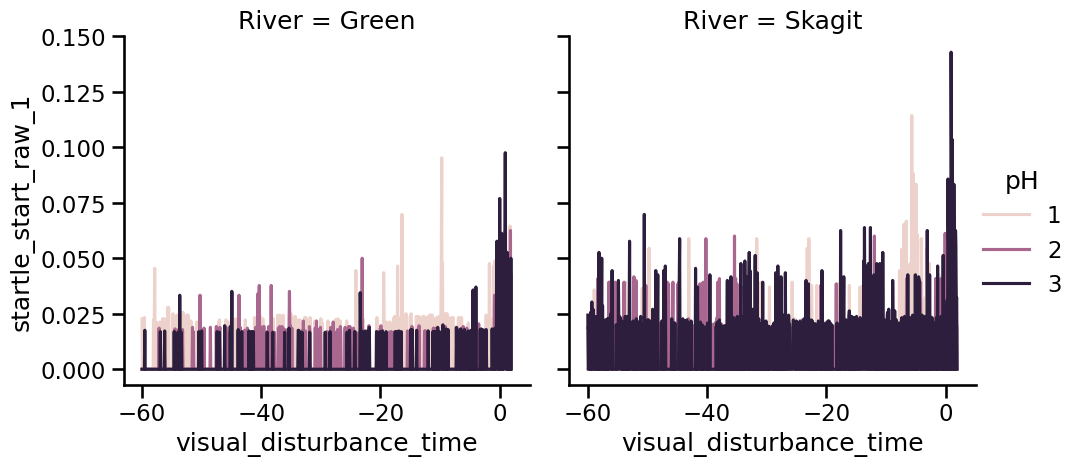

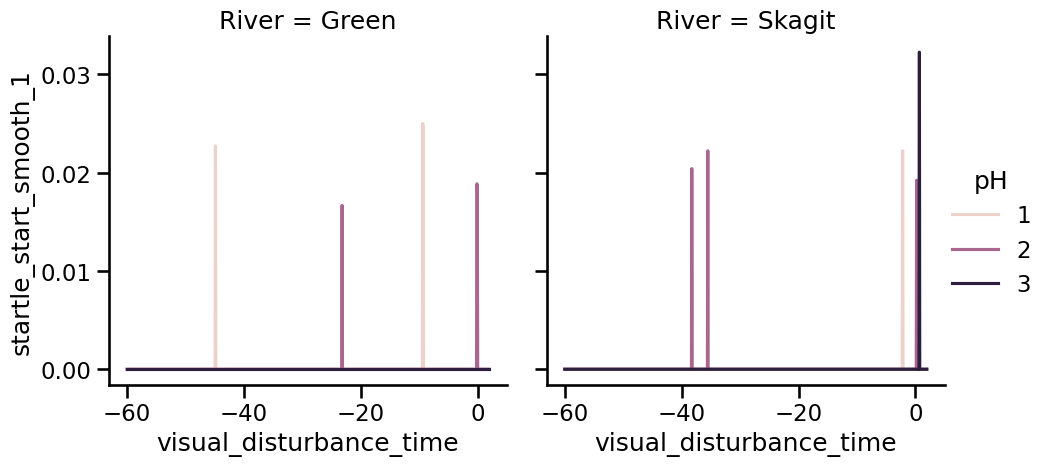

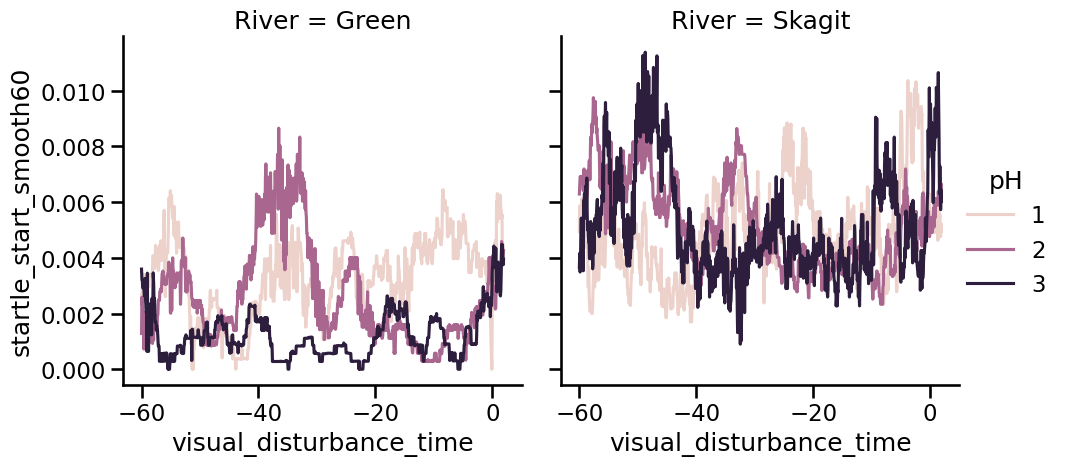

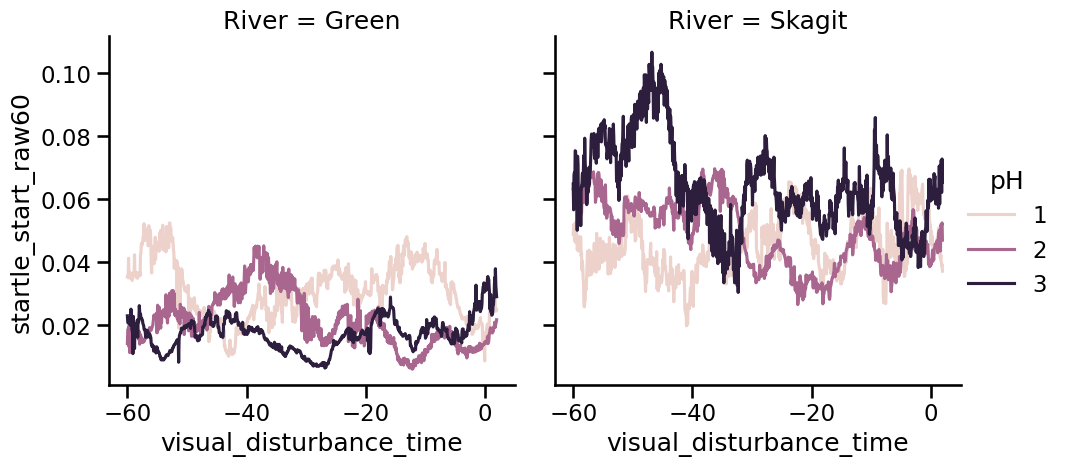

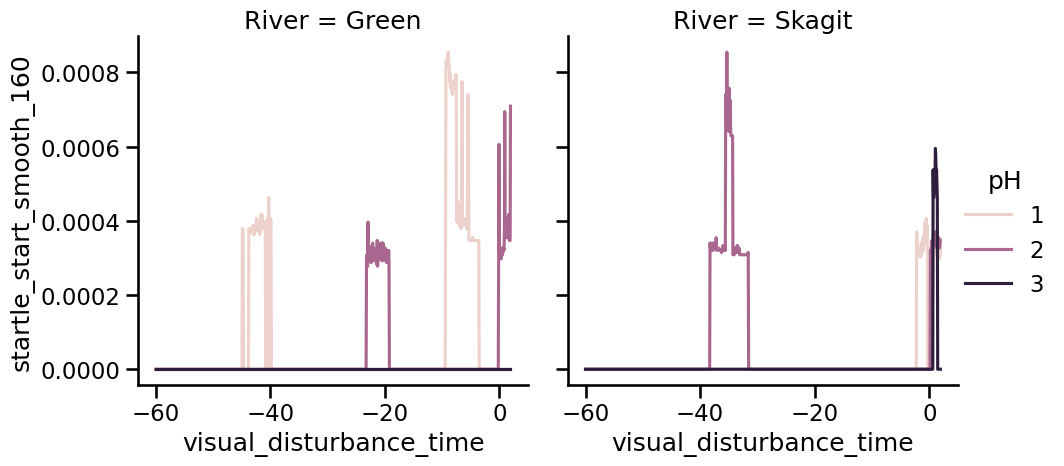

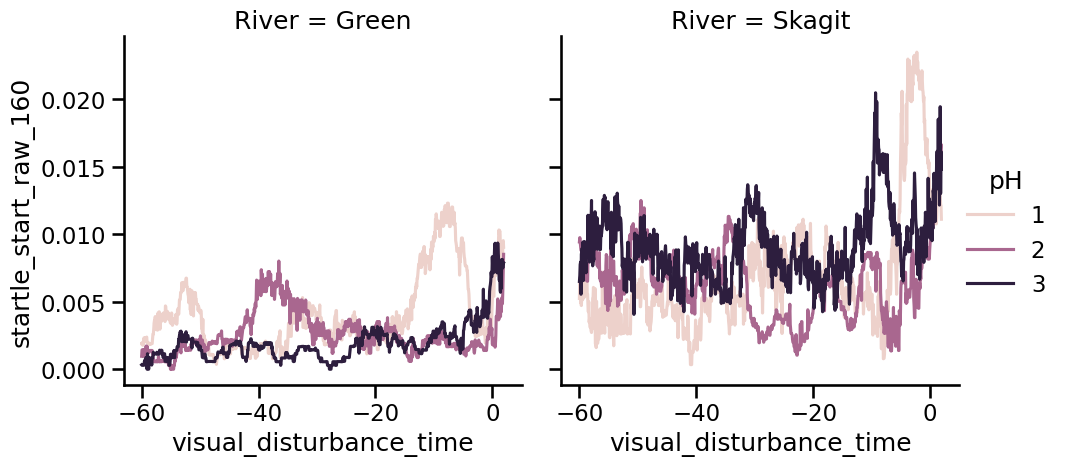

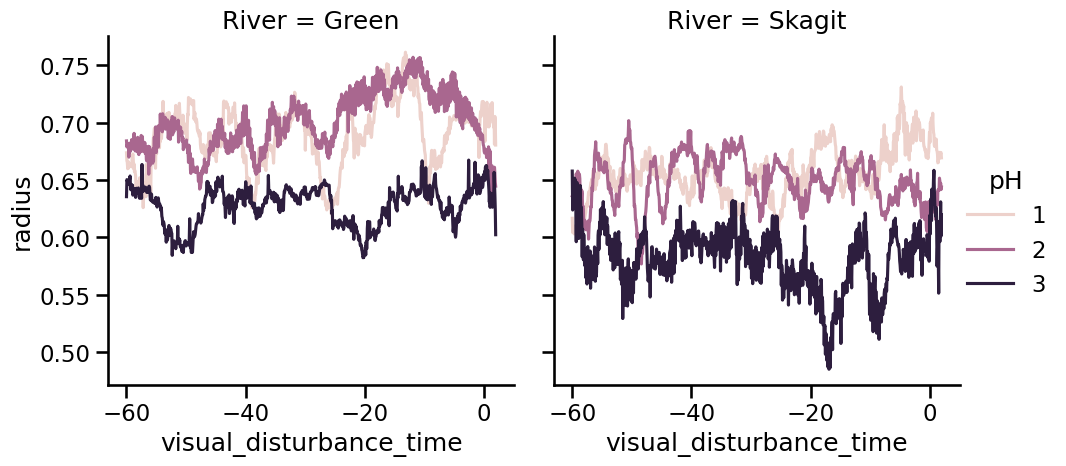

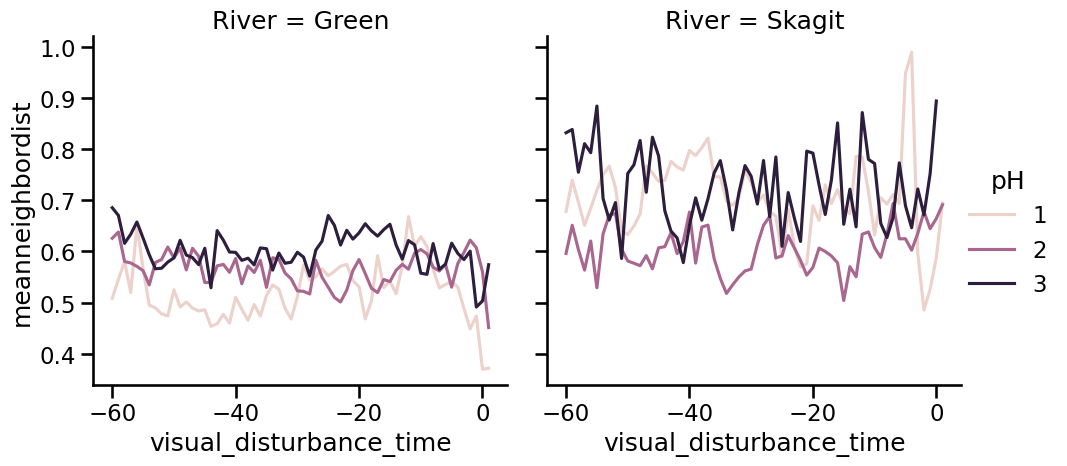

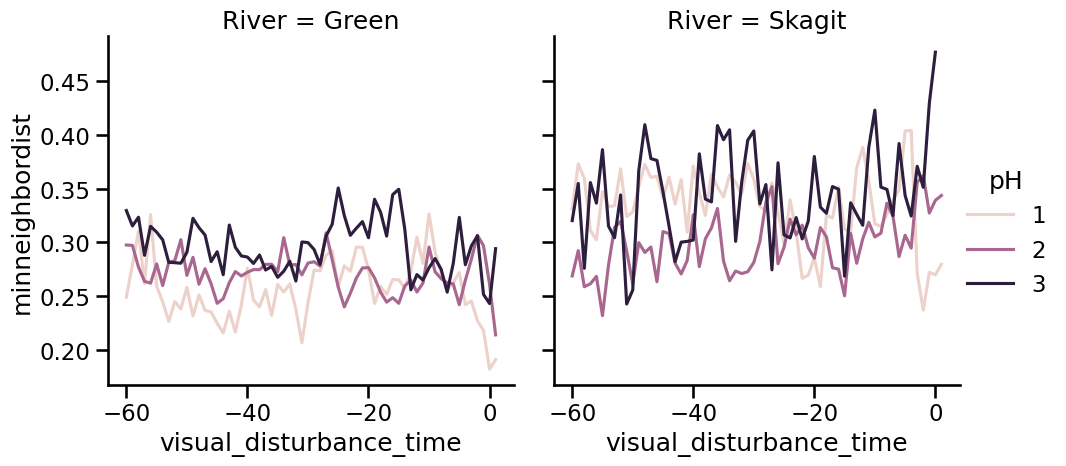

In [21]:
for _df, title, time_var in [
    # (first_10, "FIRST 10 MINUTES", "time"),
    # (pd.concat([skin_extract_before, skin_extract_after]),
    #      "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_short]),
         "BEFORE AND AFTER VISUAL DISTURBANCE short", "visual_disturbance_time"),
    # (pd.concat([visual_disturbance_before, visual_disturbance_after_long]),
    #  "BEFORE AND AFTER VISUAL DISTURBANCE long", "visual_disturbance_time"),
]:

    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df, x=time_var, y=var, kind="line", col="River", hue="pH", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)


# Delta plots

In [22]:
# Computes these intervals for before/after skin_extract time
data = []
# Groups by trial: all fish go into the mean.
GROUPBY_VARS = ["River", "pH", "Trial"]
DELTA_VARS = [
    "speed",
    "acceleration",
    "radius",
    "startle_start_raw",
    "startle_start_smooth",
    "startle_start_raw_1",
    "startle_start_smooth_1",
]


def compute_deltas(df, col_name, INTERVALS):
    a, b, c, d = INTERVALS
    for group_name, group_df in df.groupby(GROUPBY_VARS):
        before_df = group_df[
            (group_df[col_name] >= a) &
            (group_df[col_name] <= b)]
        after_df = group_df[
            (group_df[col_name] >= c) &
            (group_df[col_name] <= d)]
    
        # This is all the column values as a list.
        row = list(group_name)
    
        for delta_var in DELTA_VARS:
            delta = after_df[delta_var].replace([np.inf, -np.inf], np.nan).mean() - before_df[delta_var].replace([np.inf, -np.inf], np.nan).mean()
            row.append(delta)
            
    
        data.append(row)
    
    deltas_df = pd.DataFrame(data, columns=GROUPBY_VARS + [delta_var + "_delta" for delta_var in DELTA_VARS])
    return deltas_df

# These set up to match the intervals from above.
skin_extract_deltas = compute_deltas(df, "skin_extract_injection_time", SKIN_EXTRACT_BEFORE + SKIN_EXTRACT_AFTER)

visual_disturbance_short_deltas = compute_deltas(df, "visual_disturbance_time", VISUAL_DISTURBANCE_BEFORE + VISUAL_DISTURBANCE_AFTER_SHORT)
visual_disturbance_long_deltas = compute_deltas(df, "visual_disturbance_time", VISUAL_DISTURBANCE_BEFORE + VISUAL_DISTURBANCE_AFTER_LONG)

/Users/brendan/Library/Python/3.9/lib/python/site-packages/seaborn/axisgrid.py:453: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize)


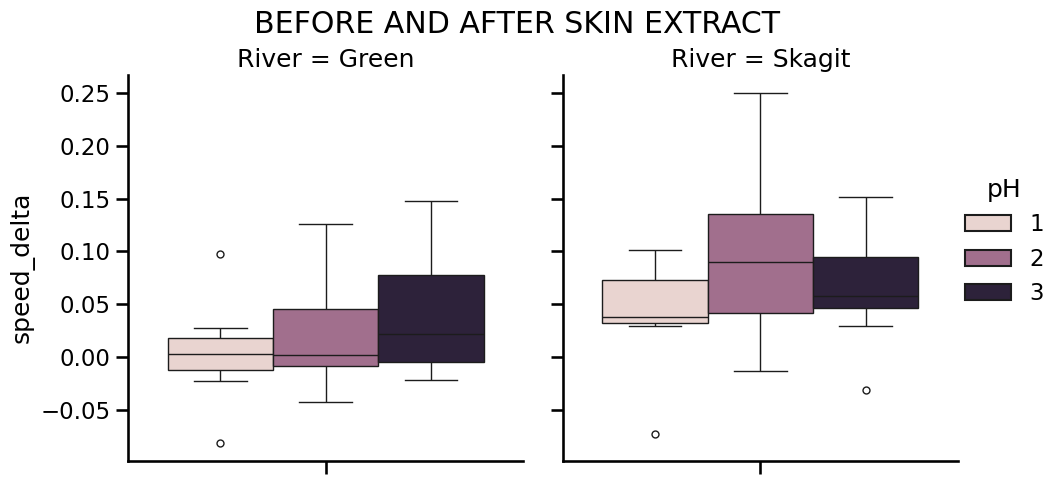

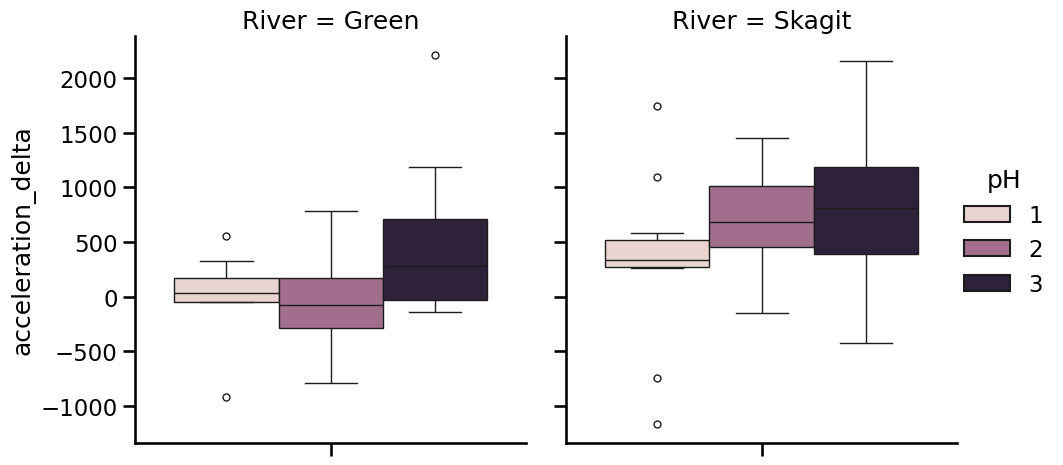

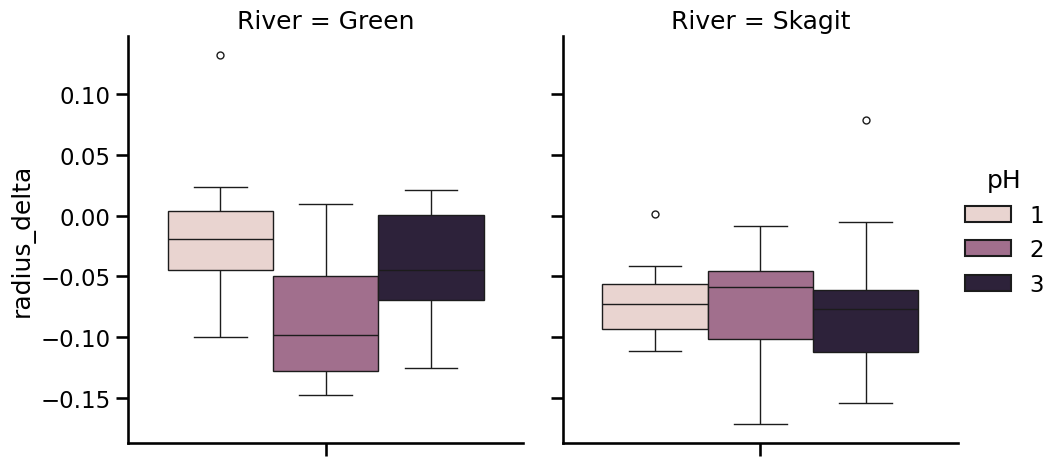

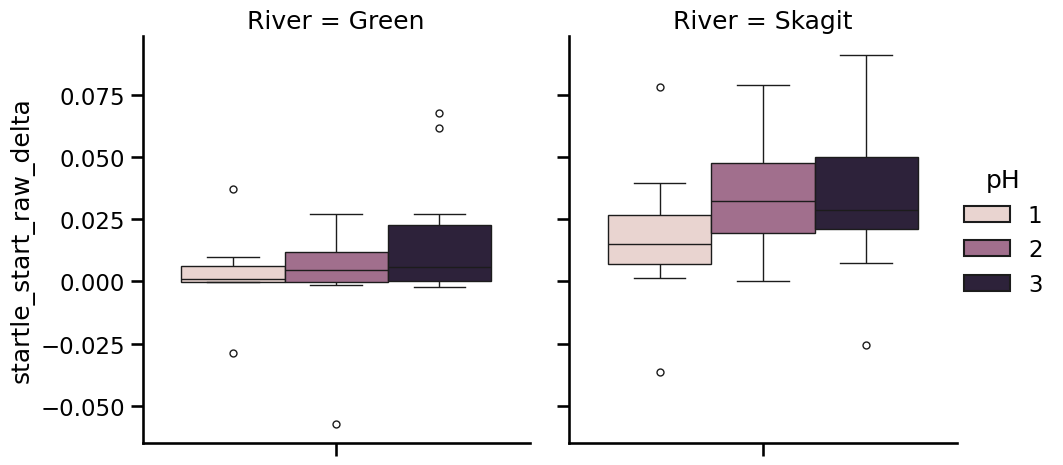

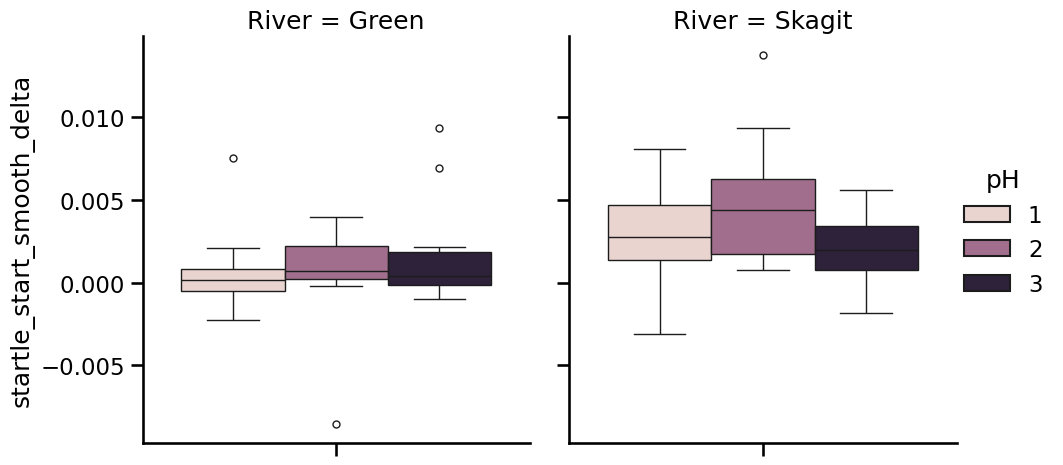

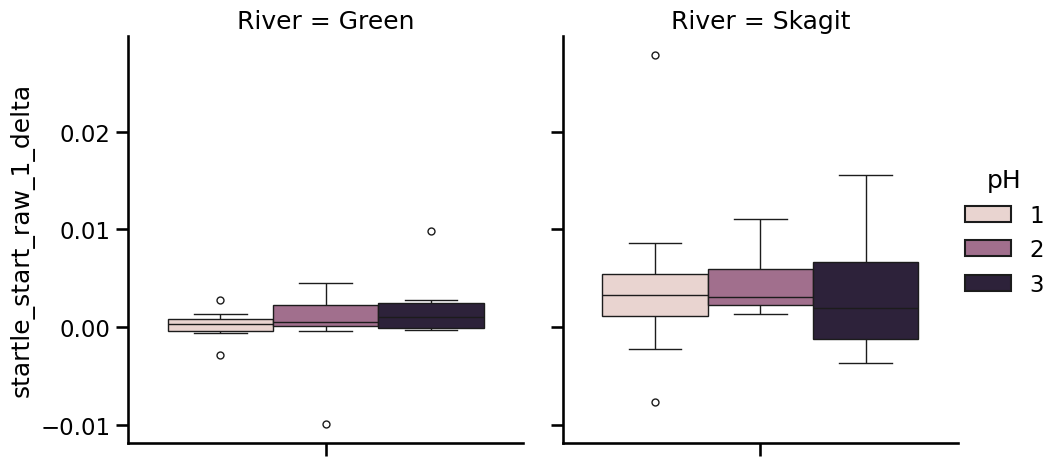

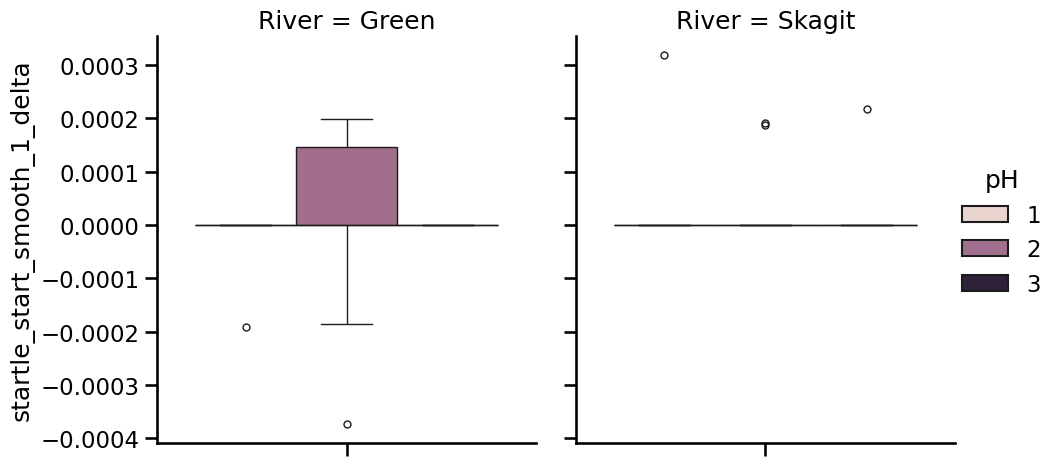

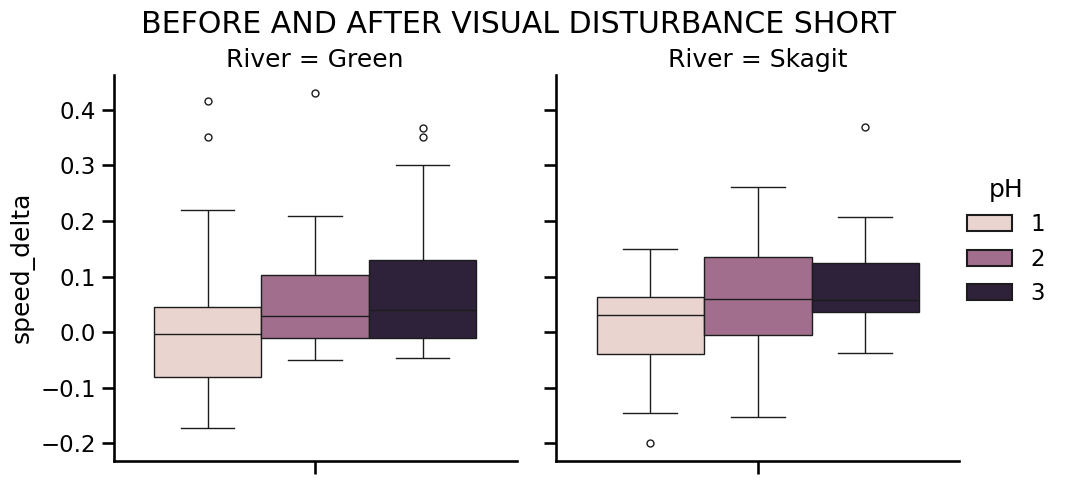

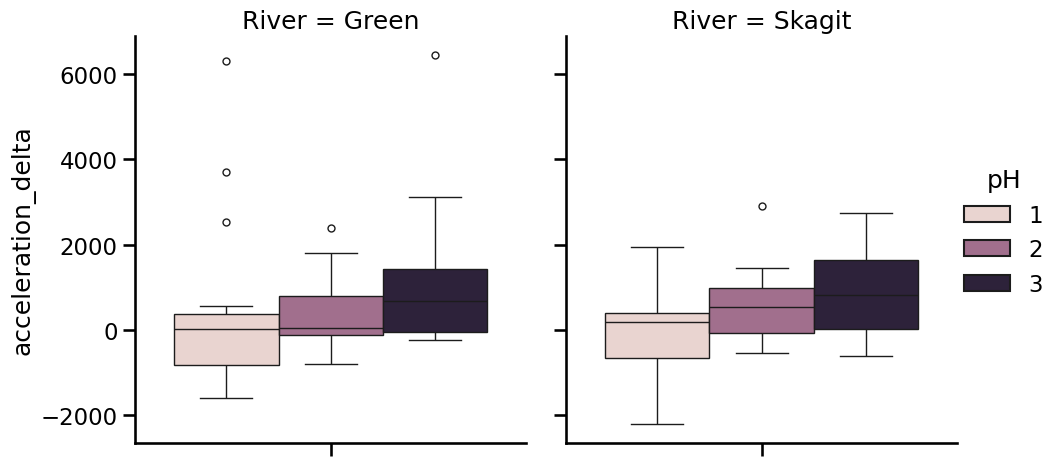

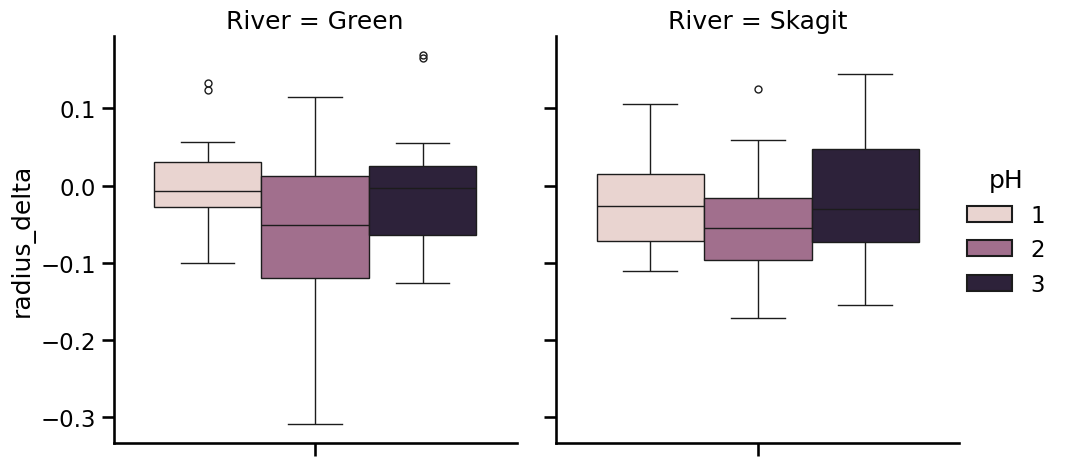

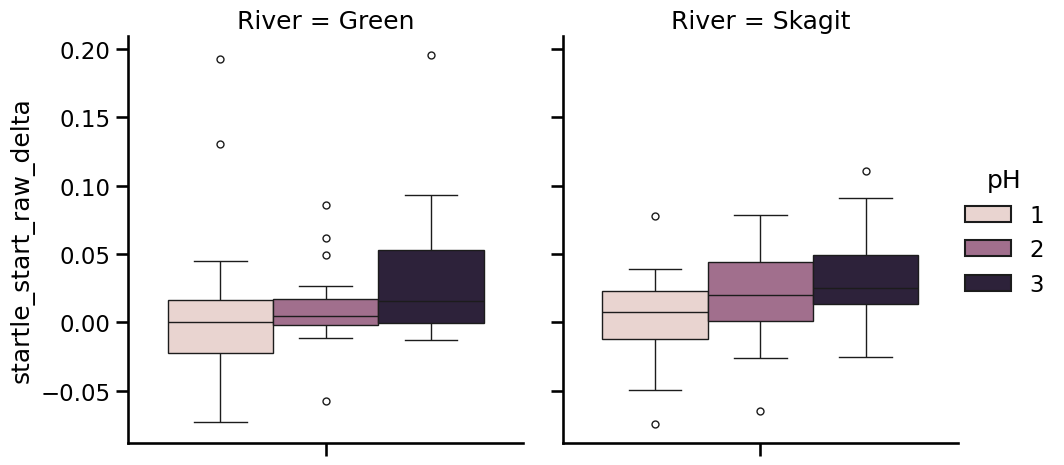

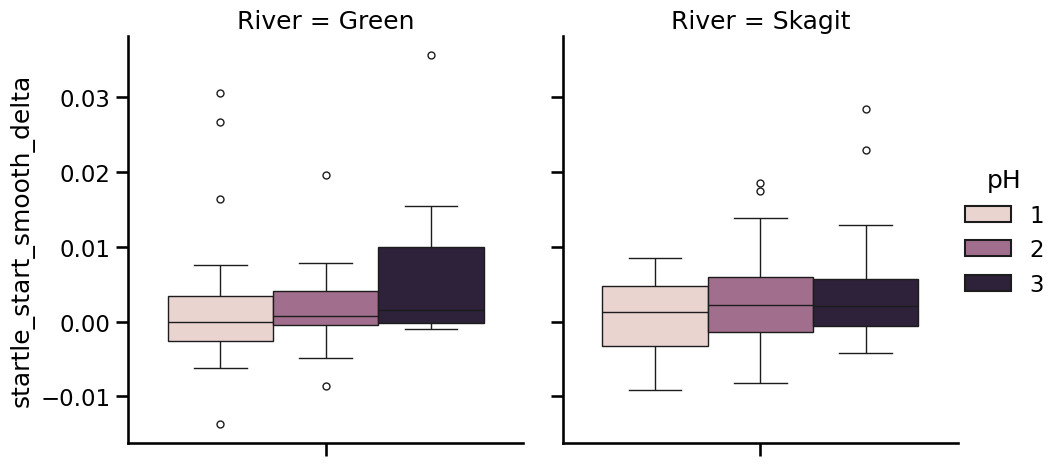

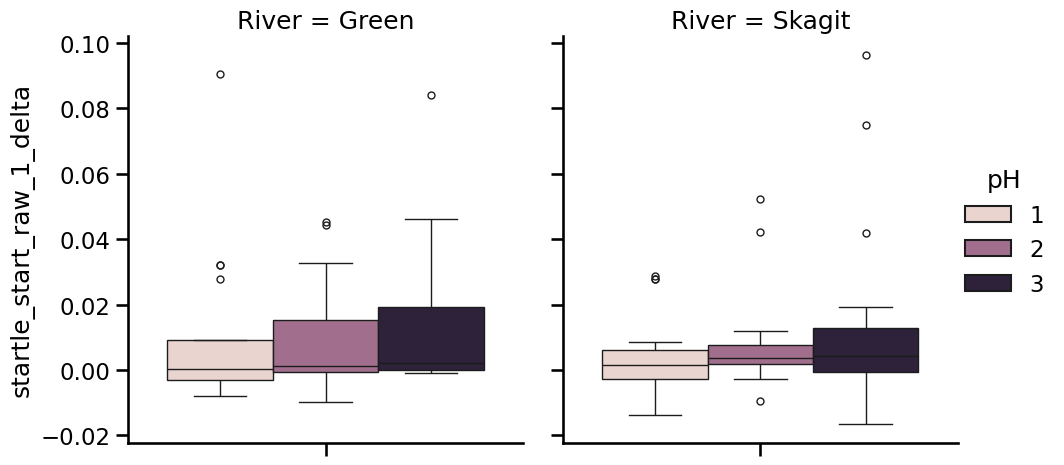

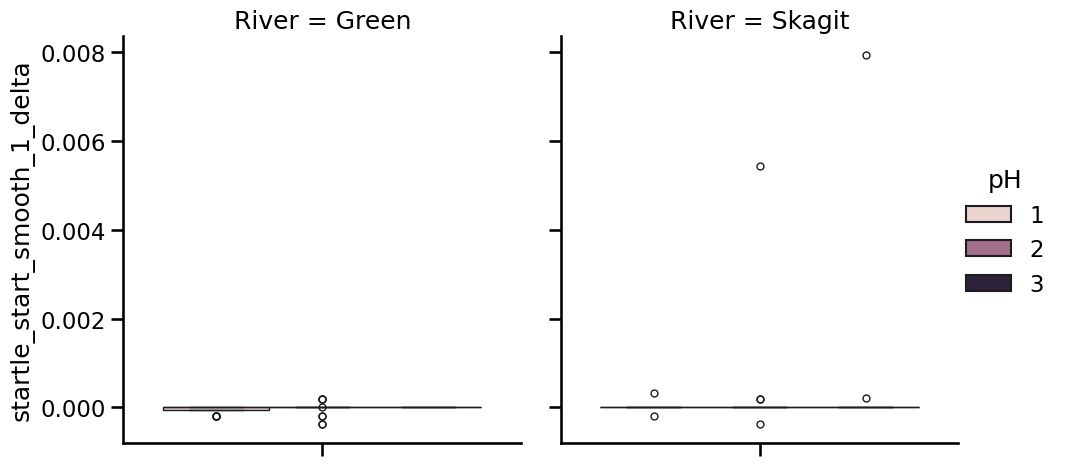

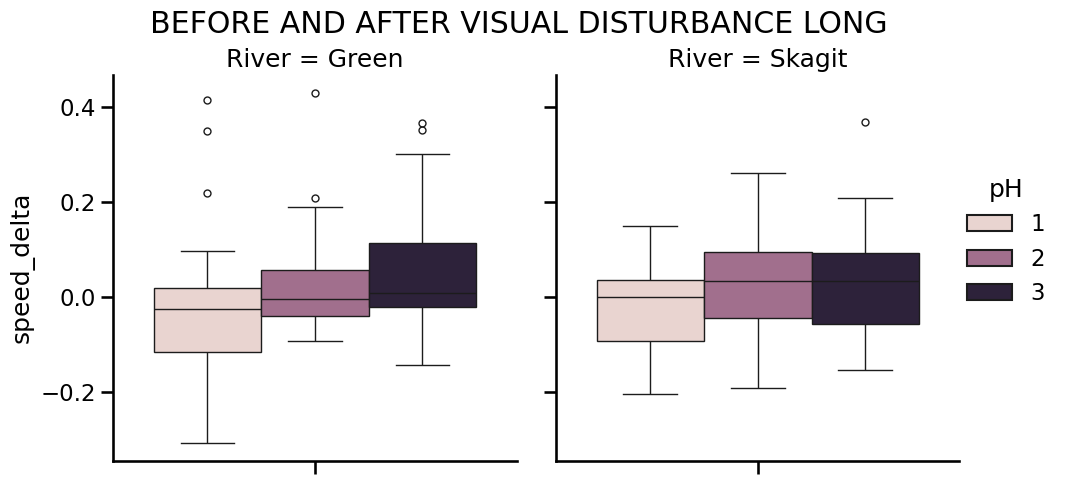

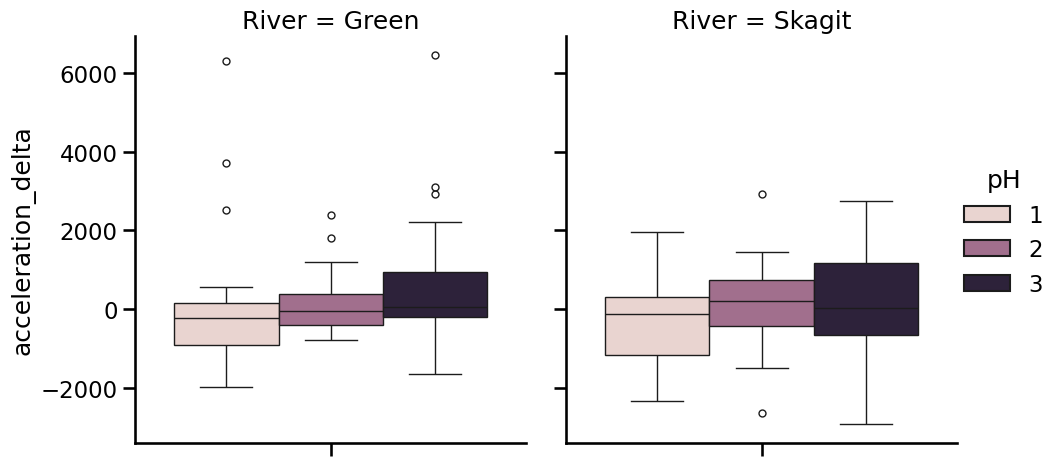

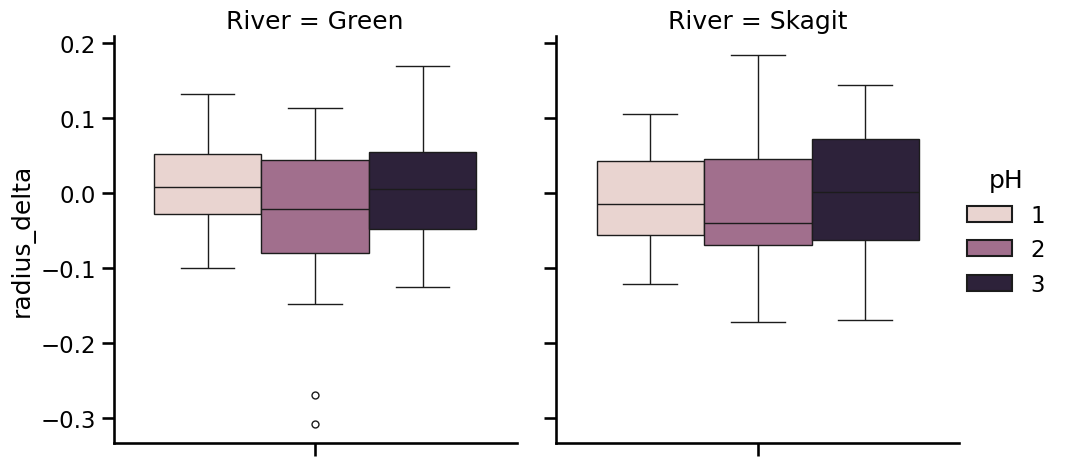

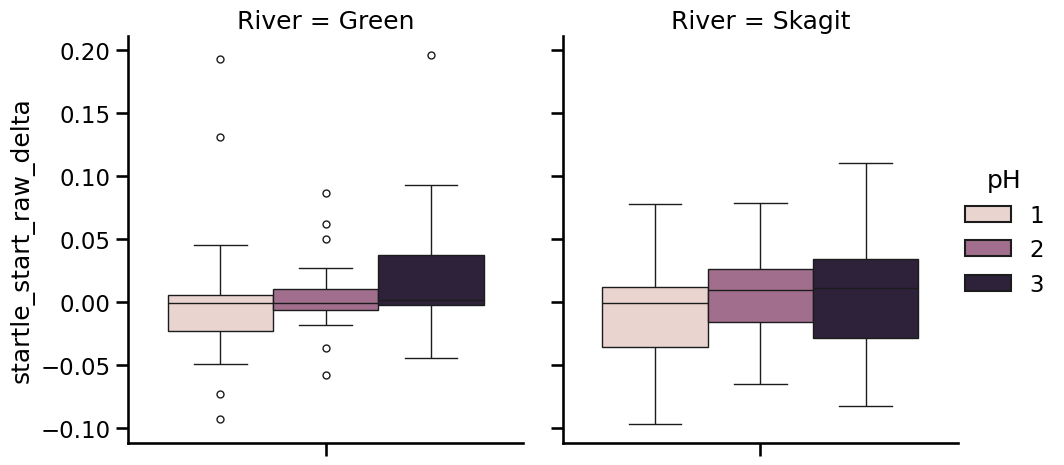

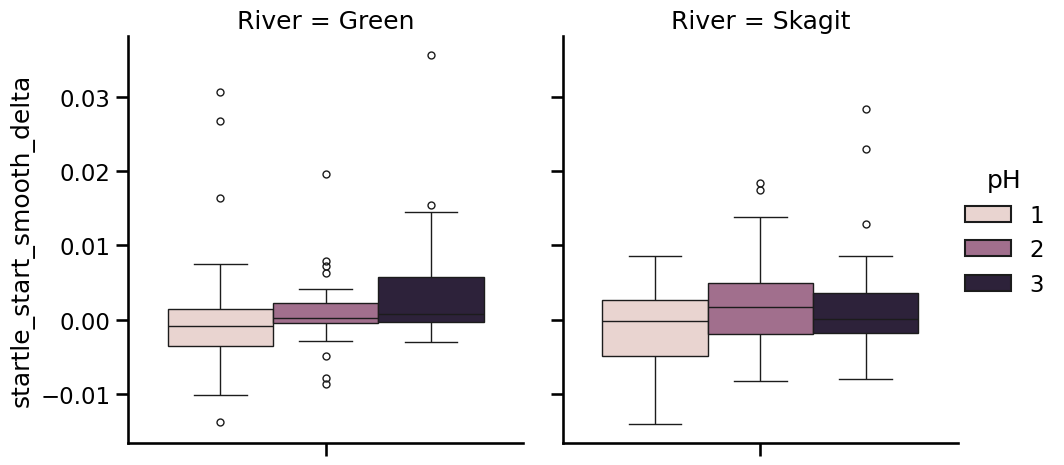

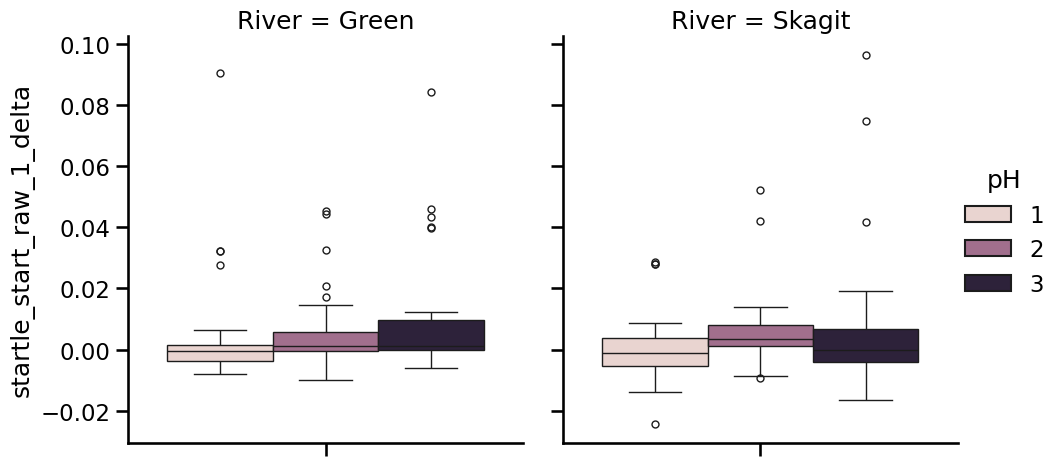

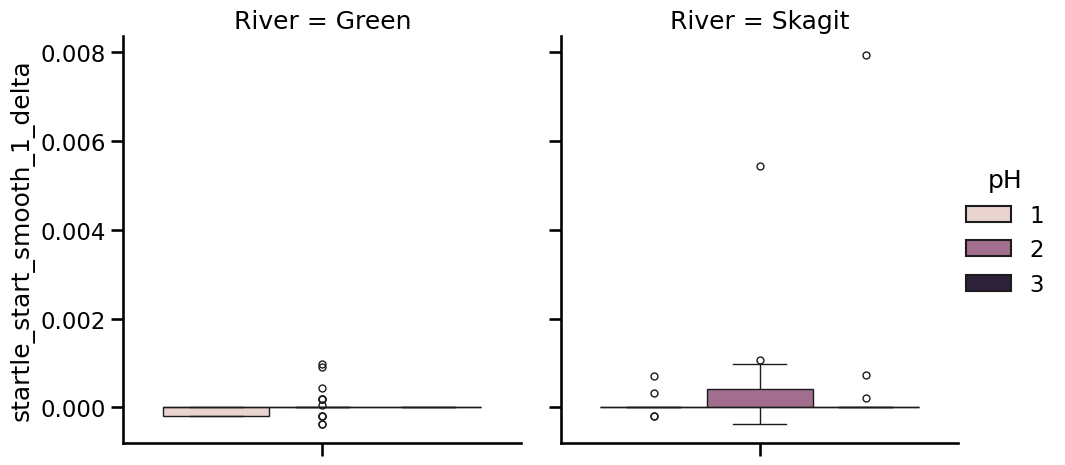

In [23]:
DELTA_VARIABLES = [var + "_delta" for var in DELTA_VARS]

for deltas_df, title in [
    (skin_extract_deltas, "BEFORE AND AFTER SKIN EXTRACT"),
    (visual_disturbance_short_deltas, "BEFORE AND AFTER VISUAL DISTURBANCE SHORT"),
    (visual_disturbance_long_deltas, "BEFORE AND AFTER VISUAL DISTURBANCE LONG"),
]:

    for i, var in enumerate(DELTA_VARIABLES):
        p = sns.catplot(
            data=deltas_df, y=var, col="River", hue="pH",
            # kind="violin",
            kind="box"
            # stat="probability",
            # bins=10,
        )

        # p.set_yscale('log')
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)



In [24]:
df.to_csv("analysis_7_combined.csv")